# Execuções com temperatura controlada (13–14/11)

1. O controle de temperatura deixou as medições mais precisas?
2. Qual limite de potência dá o menor EDP?
3. Rodar com 1 núcleo vale a pena para algum programa?

**EDP** = energia do pacote × tempo (menor é melhor). Razão = mediana de 20 execuções / mediana da referência;
entre programas, média geométrica.



## 0 · Configuração

In [1]:
import re
import zlib
from pathlib import Path

import numpy as np
import polars as pl
import polars.selectors as cs
from mizani.bounds import squish
from plotnine import (aes, coord_flip, element_blank, geom_abline, element_line, element_rect, element_text, facet_wrap,
                      geom_col, geom_hline, geom_line, geom_point, geom_segment, geom_text, geom_tile, geom_vline, ggplot,
                      labs, position_jitter, position_stack, scale_color_identity, scale_color_manual,
                      scale_fill_gradientn, scale_fill_manual, scale_shape_manual, scale_x_continuous, scale_x_discrete,
                      scale_x_log10, scale_y_continuous, scale_y_discrete, scale_y_log10, theme, theme_minimal)
from scipy.stats import rankdata, ttest_1samp, wilcoxon

pl.Config.set_tbl_rows(120)
pl.Config.set_tbl_cols(40)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_fmt_str_lengths(80)
pl.Config.set_tbl_hide_column_data_types(True)

ROOT = next(p for p in (Path('..'), Path('.')) if (p / 'data').is_dir() and (p / 'results').is_dir())
B = 2000


def key_rng(*key):
    return np.random.default_rng(zlib.crc32(repr(key).encode()))


SESSION = re.compile(r'-1[34]-11-2026')
FILES = sorted({*ROOT.glob('results/*/valid/*.csv'),
                *(p for p in ROOT.glob('data/*.csv') if SESSION.search(p.name)),
                *(p for p in ROOT.glob('results/intel-CoreUltra7/*.csv') if SESSION.search(p.name)),
                # Ryzen 8500G: 10/11 run, no temperature control. Drop this line when the controlled run is in valid/
                *ROOT.glob('results/amd-ryzen5-8500g/*.csv')})

In [2]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
DIVERGING = ['#104281', '#2a78d6', '#86b6ef', '#f0efec', '#f2a7a6', '#e34948', '#9e2a2a']   # blue = lower = better
SEQUENTIAL = ['#f0efec', '#b7d3f6', '#6da7ec', '#2a78d6', '#184f95']
SERIES = '#2a78d6'
MACHINES = ['intel-elite', 'intel-CoreUltra7', 'amd-ryzen5600gt', 'amd-ryzen5-8500g']
MACHINE_LABEL = {'intel-elite': 'intel-elite', 'intel-CoreUltra7': 'Core Ultra 7', 'amd-ryzen5600gt': 'Ryzen 5600GT',
                 'amd-ryzen5-8500g': 'Ryzen 8500G'}
MACHINE_COLOR = {'intel-elite': '#2a78d6', 'Core Ultra 7': '#eb6834', 'Ryzen 5600GT': '#1baf7a',
                 'Ryzen 8500G': '#eda100'}
LANGS = ['C', 'C++', 'Java', 'dacapo']
TOOL = {0: 'MSR', 1: 'perf'}                 # Perf: 0 = RAPL MSRs, 1 = `perf stat`
CORES = {'multi': 'all cores', 'single': '1 core'}


def cap_label(w: int) -> str:
    return 'uncapped' if w == -1 else f'{w} W'


CAPS = [2, 5, 10, 15, 25, -1]
CAP_ORDER = [cap_label(w) for w in CAPS]


def base_theme(w, h):
    return theme_minimal(base_size=9) + theme(
        figure_size=(w, h), dpi=96,
        plot_background=element_rect(fill=SURFACE, color=SURFACE),
        panel_background=element_rect(fill=SURFACE, color=SURFACE),
        panel_grid_major=element_line(color=GRID, size=0.4), panel_grid_minor=element_blank(),
        axis_text=element_text(color=INK2, size=8), axis_title=element_text(color=INK2, size=9),
        plot_title=element_text(color=INK, weight='bold', size=11.5),
        plot_subtitle=element_text(color=INK2, size=9), plot_caption=element_text(color=MUTED, size=8),
        strip_text=element_text(color=INK, weight='bold', size=8.5),
        strip_background=element_rect(fill=SURFACE, color=SURFACE),
        legend_title=element_text(color=INK2, size=8.5), legend_text=element_text(color=INK2, size=8),
        legend_background=element_rect(fill=SURFACE, color=SURFACE),
    )


HEAT = theme(panel_grid_major=element_blank(), axis_ticks=element_blank())
RATIO_BREAKS = [0.5, 0.71, 1, 1.41, 2]


def ratio_fill(name, labels=('0.5× better', '0.71×', '1×', '1.41×', '≥2× worse')):
    # log2(ratio) clipped to ±1, i.e. 0.5× … 2×, symmetric around 1×
    return scale_fill_gradientn(colors=DIVERGING, limits=(-1, 1), oob=squish, name=name,
                                breaks=np.log2(RATIO_BREAKS).tolist(), labels=list(labels))


def pct_text(col: str) -> pl.Expr:
    p = ((pl.col(col) - 1) * 100).round(0).cast(pl.Int64)
    return (pl.when(pl.col(col) >= 10).then(pl.format('×{}', pl.col(col).round(0).cast(pl.Int64)))
              .when(p > 0).then(pl.format('+{}%', p))
              .otherwise(pl.format('{}%', p).str.replace('-', '−')))


def tile_text_color(col='l2'):
    return pl.when(pl.col(col).abs() > 0.55).then(pl.lit('#ffffff')).otherwise(pl.lit(INK))


def gmean(col: str) -> pl.Expr:
    return pl.col(col).log().mean().exp()


def as_pct(*cols):
    return [((pl.col(c) - 1) * 100).round(1).alias(f'{c} %') for c in cols]

## 1 · Leitura



In [3]:
CANON = {
    'Language': 'language', 'Program': 'program', 'PowerLimit': 'power_limit',
    'PSys': 'psys_j', 'PSys-Fake': 'psys_fake_j', 'Package': 'pkg_j', 'Core': 'core_j', 'GPU': 'gpu_j',
    'DRAM': 'dram_j', 'DRAM-Fake': 'dram_fake_j', 'Time(ms)': 'time_ms', 'User Time': 'user_ms',
    'System Time': 'sys_ms', 'Cache References': 'cache_refs', 'Cache Misses': 'cache_misses',
    'Temperature': 'temp_c', 'Memory': 'mem_kb', 'Perf': 'perf',
}
NUMERIC = ['psys_j', 'psys_fake_j', 'pkg_j', 'core_j', 'gpu_j', 'dram_j', 'dram_fake_j', 'time_ms', 'user_ms',
           'sys_ms', 'cache_refs', 'cache_misses', 'temp_c', 'mem_kb']


def read_campaign(path: Path) -> pl.DataFrame:
    header = [h.strip() for h in path.open().readline().split(',')]
    body = pl.read_csv(path, has_header=False, skip_rows=1, infer_schema=False, quote_char=None,
                       comment_prefix='Error')
    cols = header
    if body.width == len(header) - 1 and 'Cache Misses' in header:
        cols = [h for h in header if h != 'Cache Misses']        # Perf = 0 rows never write Cache Misses
    if body.width != len(cols):
        raise ValueError(f'{path}: {body.width} fields per row but {len(cols)} header names')
    return (body.rename(dict(zip(body.columns, [CANON[c] for c in cols])))
                .with_columns(pl.all().str.strip_chars().replace('', None)))


def campaign_meta(path: Path) -> dict:
    d, m, y = re.search(r'(\d{2})-(\d{2})-(\d{4})', path.name).groups()
    machine = path.parent.parent.name if path.parent.name == 'valid' else path.parent.name
    machine = 'intel-elite' if machine == 'data' else machine     # data/ holds the intel-elite runs
    return {'source': str(path.relative_to(ROOT)), 'machine': machine, 'date': f'{y}-{m}-{d}',
            'cores': 'single' if path.name.startswith('single') else 'multi',
            'suite': 'DaCapo' if 'dacapo' in path.name else 'CLBG'}


raw = (pl.concat([read_campaign(p).with_columns(**{k: pl.lit(v) for k, v in campaign_meta(p).items()})
                  for p in FILES], how='diagonal_relaxed')
         .with_columns(pl.col('power_limit').cast(pl.Int32), pl.col('perf').cast(pl.Int8, strict=False),
                       cs.by_name(NUMERIC, require_all=False).cast(pl.Float64, strict=False))
         .with_columns(run=pl.int_range(pl.len()).over('source', 'language', 'program', 'power_limit'),
                       seq=pl.int_range(pl.len()).over('source')))
print(f'{raw.height} rows from {raw["source"].n_unique()} files')

cells = raw.group_by('source', 'language', 'program', 'power_limit').len()
(raw.group_by('source', maintain_order=True)
    .agg(machine=pl.col('machine').first(), suite=pl.col('suite').first(), cores=pl.col('cores').first(),
         tool=pl.col('perf').max().replace_strict(TOOL, return_dtype=pl.String), date=pl.col('date').first(),
         rows=pl.len(), programs=(pl.col('language') + pl.col('program')).n_unique(),
         caps=pl.col('power_limit').unique().sort().cast(pl.String).str.join(' '),
         temp_min=pl.col('temp_c').min(), temp_max=pl.col('temp_c').max())
    .join(cells.group_by('source').agg(runs_min=pl.col('len').min(), runs_max=pl.col('len').max()), on='source')
    .drop('source').sort('machine', 'suite', 'cores', 'tool'))

40967 rows from 14 files


machine,suite,cores,tool,date,rows,programs,caps,temp_min,temp_max,runs_min,runs_max
"""amd-ryzen5-8500g""","""CLBG""","""multi""","""perf""","""2026-11-10""",3240,27,"""-1 2 5 10 15 25""",30.1,69.2,20,20
"""amd-ryzen5-8500g""","""DaCapo""","""multi""","""perf""","""2026-11-10""",1206,22,"""-1 10 15""",32.6,77.9,1,20
"""amd-ryzen5600gt""","""CLBG""","""multi""","""perf""","""2026-11-13""",3126,27,"""-1 2 5 10 15 25""",28.8,76.9,1,20
"""amd-ryzen5600gt""","""CLBG""","""single""","""perf""","""2026-11-14""",3126,27,"""-1 2 5 10 15 25""",28.6,65.6,1,20
"""amd-ryzen5600gt""","""DaCapo""","""multi""","""perf""","""2026-11-13""",2165,22,"""-1 2 5 10 15 25""",28.6,79.4,1,20
"""amd-ryzen5600gt""","""DaCapo""","""single""","""perf""","""2026-11-14""",2184,22,"""-1 2 5 10 15 25""",28.5,65.5,1,20
"""intel-CoreUltra7""","""CLBG""","""multi""","""MSR""","""2026-11-13""",3240,27,"""-1 2 5 10 15 25""",32.6,56.6,20,20
"""intel-CoreUltra7""","""CLBG""","""multi""","""perf""","""2026-11-13""",3240,27,"""-1 2 5 10 15 25""",32.5,56.5,20,20
"""intel-CoreUltra7""","""CLBG""","""single""","""MSR""","""2026-11-13""",3240,27,"""-1 2 5 10 15 25""",34.0,56.0,20,20
"""intel-CoreUltra7""","""CLBG""","""single""","""perf""","""2026-11-14""",3240,27,"""-1 2 5 10 15 25""",34.0,54.0,20,20


## 2 · Limpeza

In [4]:
issues = []


def log_issue(check, where, rows, action):
    issues.append({'check': check, 'where': where, 'rows': rows, 'action': action})


# 2.1 programs that failed: ProgramError lines (no numeric energy/time) or runs that recorded 0 J in 0 ms
failed = (raw.with_columns(kind=pl.when(pl.col('pkg_j').is_null() | pl.col('time_ms').is_null())
                                  .then(pl.lit('ProgramError'))
                                  .when((pl.col('pkg_j') == 0) & (pl.col('time_ms') == 0)).then(pl.lit('all zeros')))
             .filter(pl.col('kind').is_not_null()))
failed_summary = (failed.group_by('machine', 'suite', 'kind', 'language', 'program')
                        .agg(rows=pl.len(), files=pl.col('source').n_unique(),
                             caps=pl.col('power_limit').unique().sort().cast(pl.String).str.join(' '))
                        .sort('machine', 'suite', 'kind', 'program'))
display(failed_summary)
for (m, s, k), g in failed_summary.group_by('machine', 'suite', 'kind', maintain_order=True):
    log_issue(f'program failed ({k})', f'{MACHINE_LABEL[m]} · {s}: ' + ', '.join(g['program']), int(g['rows'].sum()),
              'dropped')
step = raw.join(failed.select('source', 'language', 'program', 'power_limit', 'run'),
                on=['source', 'language', 'program', 'power_limit', 'run'], how='anti')

machine,suite,kind,language,program,rows,files,caps
"""amd-ryzen5-8500g""","""DaCapo""","""ProgramError""","""dacapo""","""cassandra""",3,1,"""-1 10 15"""
"""amd-ryzen5-8500g""","""DaCapo""","""ProgramError""","""dacapo""","""h2o""",3,1,"""-1 10 15"""
"""amd-ryzen5-8500g""","""DaCapo""","""all zeros""","""dacapo""","""eclipse""",3,1,"""-1"""
"""amd-ryzen5600gt""","""CLBG""","""ProgramError""","""C++""","""binary-trees""",12,2,"""-1 2 5 10 15 25"""
"""amd-ryzen5600gt""","""DaCapo""","""ProgramError""","""dacapo""","""cassandra""",12,2,"""-1 2 5 10 15 25"""
"""amd-ryzen5600gt""","""DaCapo""","""ProgramError""","""dacapo""","""h2o""",12,2,"""-1 2 5 10 15 25"""
"""amd-ryzen5600gt""","""DaCapo""","""ProgramError""","""dacapo""","""pmd""",1,1,"""-1"""
"""amd-ryzen5600gt""","""DaCapo""","""ProgramError""","""dacapo""","""tradebeans""",12,2,"""-1 2 5 10 15 25"""
"""amd-ryzen5600gt""","""DaCapo""","""ProgramError""","""dacapo""","""tradesoap""",12,2,"""-1 2 5 10 15 25"""
"""amd-ryzen5600gt""","""DaCapo""","""all zeros""","""dacapo""","""eclipse""",240,2,"""-1 2 5 10 15 25"""


* 5600GT: C++ binary-trees falha em todos os limites.
* DaCapo: só 10 de 22 programas rodaram (4 com erro, 8 gravam 0 J em 0 ms).
* 8500G: só cassandra e h2o falham (esperado); eclipse perde 3 execuções com 0 J. Os 8 programas zerados no 5600GT
  rodam normalmente aqui.

In [5]:
# 2.2 RAPL wraparound: with Perf = 0 the package energy is the difference of two reads of a 32-bit counter
# (unit 2^-14 J), so a run that crosses the wrap comes out negative by exactly 2^32 * 2^-14 J
WRAP_J = 2**32 * 2**-14
neg = step.filter(pl.col('pkg_j') < 0)
cell_W = (step.filter(pl.col('pkg_j') > 0).group_by('source', 'language', 'program', 'power_limit')
              .agg(cell_median_W=(pl.col('pkg_j') / (pl.col('time_ms') / 1000)).median()))
display(neg.join(cell_W, on=['source', 'language', 'program', 'power_limit'])
           .select('source', 'language', 'program', 'power_limit', 'run', 'pkg_j', 'core_j',
                   fixed_W=(pl.col('pkg_j') + WRAP_J) / (pl.col('time_ms') / 1000), cell_median_W='cell_median_W')
           .with_columns(cs.float().round(2)).sort('source', 'run'))
step = step.with_columns(pkg_j=pl.when(pl.col('pkg_j') < 0).then(pl.col('pkg_j') + WRAP_J).otherwise('pkg_j'))
log_issue('RAPL counter wraparound', ', '.join(neg['source']), neg.height, '+262 144 J (matches the cell power)')

source,language,program,power_limit,run,pkg_j,core_j,fixed_W,cell_median_W
"""data/single-measurements-perf-0-13-11-2026-23:57:36.csv""","""C++""","""fasta""",-1,18,-262130.52,11.05,1.97,1.96
"""results/intel-CoreUltra7/single-measuremnets-perf-0-13-11-2026-21:55:27.csv""","""Java""","""fannkuch-redux""",10,6,-261716.02,188.82,10.09,10.09


Contador RAPL estourou em 2 execuções MSR

In [6]:
# 2.3 derived columns and labels
clean = (step
         .with_columns(E=pl.col('pkg_j'), T=pl.col('time_ms') / 1000,
                       tool=pl.col('perf').replace_strict(TOOL, return_dtype=pl.String),
                       machine_label=pl.col('machine').replace_strict(MACHINE_LABEL, return_dtype=pl.String),
                       cores_label=pl.col('cores').replace_strict(CORES, return_dtype=pl.String),
                       bench=pl.format('{} · {}', 'language', 'program'))
         .with_columns(P=pl.col('E') / pl.col('T'), EDP=pl.col('E') * pl.col('T'),
                       group=pl.format('{} · {}', 'machine_label', 'suite'))
         .with_columns(setup=pl.format('{} · {}', 'group', 'cores_label'))
         .with_columns(campaign=pl.format('{} · {}', 'setup', 'tool')))

order = (clean.select('machine', 'suite', 'group', 'setup', 'campaign', 'cores', 'tool').unique()
              .with_columns(m=pl.col('machine').replace_strict({m: i for i, m in enumerate(MACHINES)}))
              .sort('m', 'suite', 'cores', 'tool'))
GROUPS = order['group'].unique(maintain_order=True).to_list()
SETUPS = order['setup'].unique(maintain_order=True).to_list()
CAMPAIGNS = order['campaign'].to_list()
BENCHES = (clean.select('language', 'program', 'bench').unique()
                .with_columns(l=pl.col('language').replace_strict({x: i for i, x in enumerate(LANGS)}))
                .sort('l', 'program')['bench'].to_list())
clean = clean.with_columns(group=pl.col('group').cast(pl.Enum(GROUPS)), setup=pl.col('setup').cast(pl.Enum(SETUPS)),
                           campaign=pl.col('campaign').cast(pl.Enum(CAMPAIGNS)),
                           bench=pl.col('bench').cast(pl.Enum(BENCHES)),
                           cap=pl.col('power_limit').map_elements(cap_label, return_dtype=pl.String)
                                 .cast(pl.Enum(CAP_ORDER)))
print(f'{clean.height} clean runs in {len(CAMPAIGNS)} campaigns')

38977 clean runs in 14 campaigns


### 2.1 A execução sem limite estava sem limite?

Sem limite de verdade, a potência é várias vezes a de 2 W. Campanha com razão < 1.5 é marcada.

In [7]:
med = clean.group_by('campaign', 'bench', 'power_limit').agg(pl.col('T', 'P', 'temp_c').median())
wide = med.filter(pl.col('power_limit').is_in([-1, 2, 25])).pivot(on='power_limit', index=['campaign', 'bench'],
                                                                   values=['T', 'P', 'temp_c'])
baseline = (wide.group_by('campaign')
                .agg(time_uncapped_over_2W=(pl.col('T_-1') / pl.col('T_2')).log().mean().exp(),
                     power_uncapped_over_2W=(pl.col('P_-1') / pl.col('P_2')).log().mean().exp(),
                     uncapped_W_max=pl.col('P_-1').max(), cap25_W_max=pl.col('P_25').max(),
                     temp_uncapped=pl.col('temp_c_-1').median(), temp_2W=pl.col('temp_c_2').median())
                .with_columns(inherited_cap=pl.col('power_uncapped_over_2W') < 1.5)
                .sort('campaign').with_columns(cs.float().round(2)))
BAD_BASELINE = baseline.filter('inherited_cap')['campaign'].cast(pl.String).to_list()
log_issue('uncapped block inherited a ~2 W cap', ', '.join(BAD_BASELINE),
          clean.filter(pl.col('campaign').cast(pl.String).is_in(BAD_BASELINE), pl.col('power_limit') == -1).height,
          'kept, excluded from comparisons against uncapped')
clean = clean.with_columns(baseline_ok=~pl.col('campaign').cast(pl.String).is_in(BAD_BASELINE))
baseline

campaign,time_uncapped_over_2W,power_uncapped_over_2W,uncapped_W_max,cap25_W_max,temp_uncapped,temp_2W,inherited_cap
"""intel-elite · CLBG · all cores · MSR""",1.0,1.0,3.88,24.79,41.5,40.0,true
"""intel-elite · CLBG · all cores · perf""",0.99,0.98,3.94,24.93,40.2,39.0,true
"""intel-elite · CLBG · 1 core · MSR""",0.97,0.99,2.05,14.02,39.0,39.0,true
"""intel-elite · CLBG · 1 core · perf""",0.57,1.0,2.25,14.07,39.0,39.0,true
"""Core Ultra 7 · CLBG · all cores · MSR""",0.1,5.63,180.72,33.79,43.5,33.85,false
"""Core Ultra 7 · CLBG · all cores · perf""",0.1,5.63,180.1,32.31,42.0,33.4,false
"""Core Ultra 7 · CLBG · 1 core · MSR""",0.07,3.22,28.11,25.04,52.0,34.0,false
"""Core Ultra 7 · CLBG · 1 core · perf""",0.08,3.24,28.07,25.08,52.0,34.0,false
"""Ryzen 5600GT · CLBG · all cores · perf""",0.09,7.2,42.23,25.53,65.65,29.25,false
"""Ryzen 5600GT · CLBG · 1 core · perf""",0.07,4.35,16.73,16.71,53.45,28.95,false


* **`intel-elite`: não.** O bloco sem limite das quatro campanhas rodou sob ~2 W (razão 0.98–1.00; nas outras máquinas,
  3–7×). Provável limite herdado dos registradores.
* 8500G: sim (CLBG 5×). O DaCapo dele não tem 2 W para comparar, mas sem limite chega a 53 W, bem acima de 15 W.
* O `intel-elite` fica fora das comparações com a execução sem limite (estimativa na 4.5). **Rodar de novo o bloco `-1`
  após um reboot.**

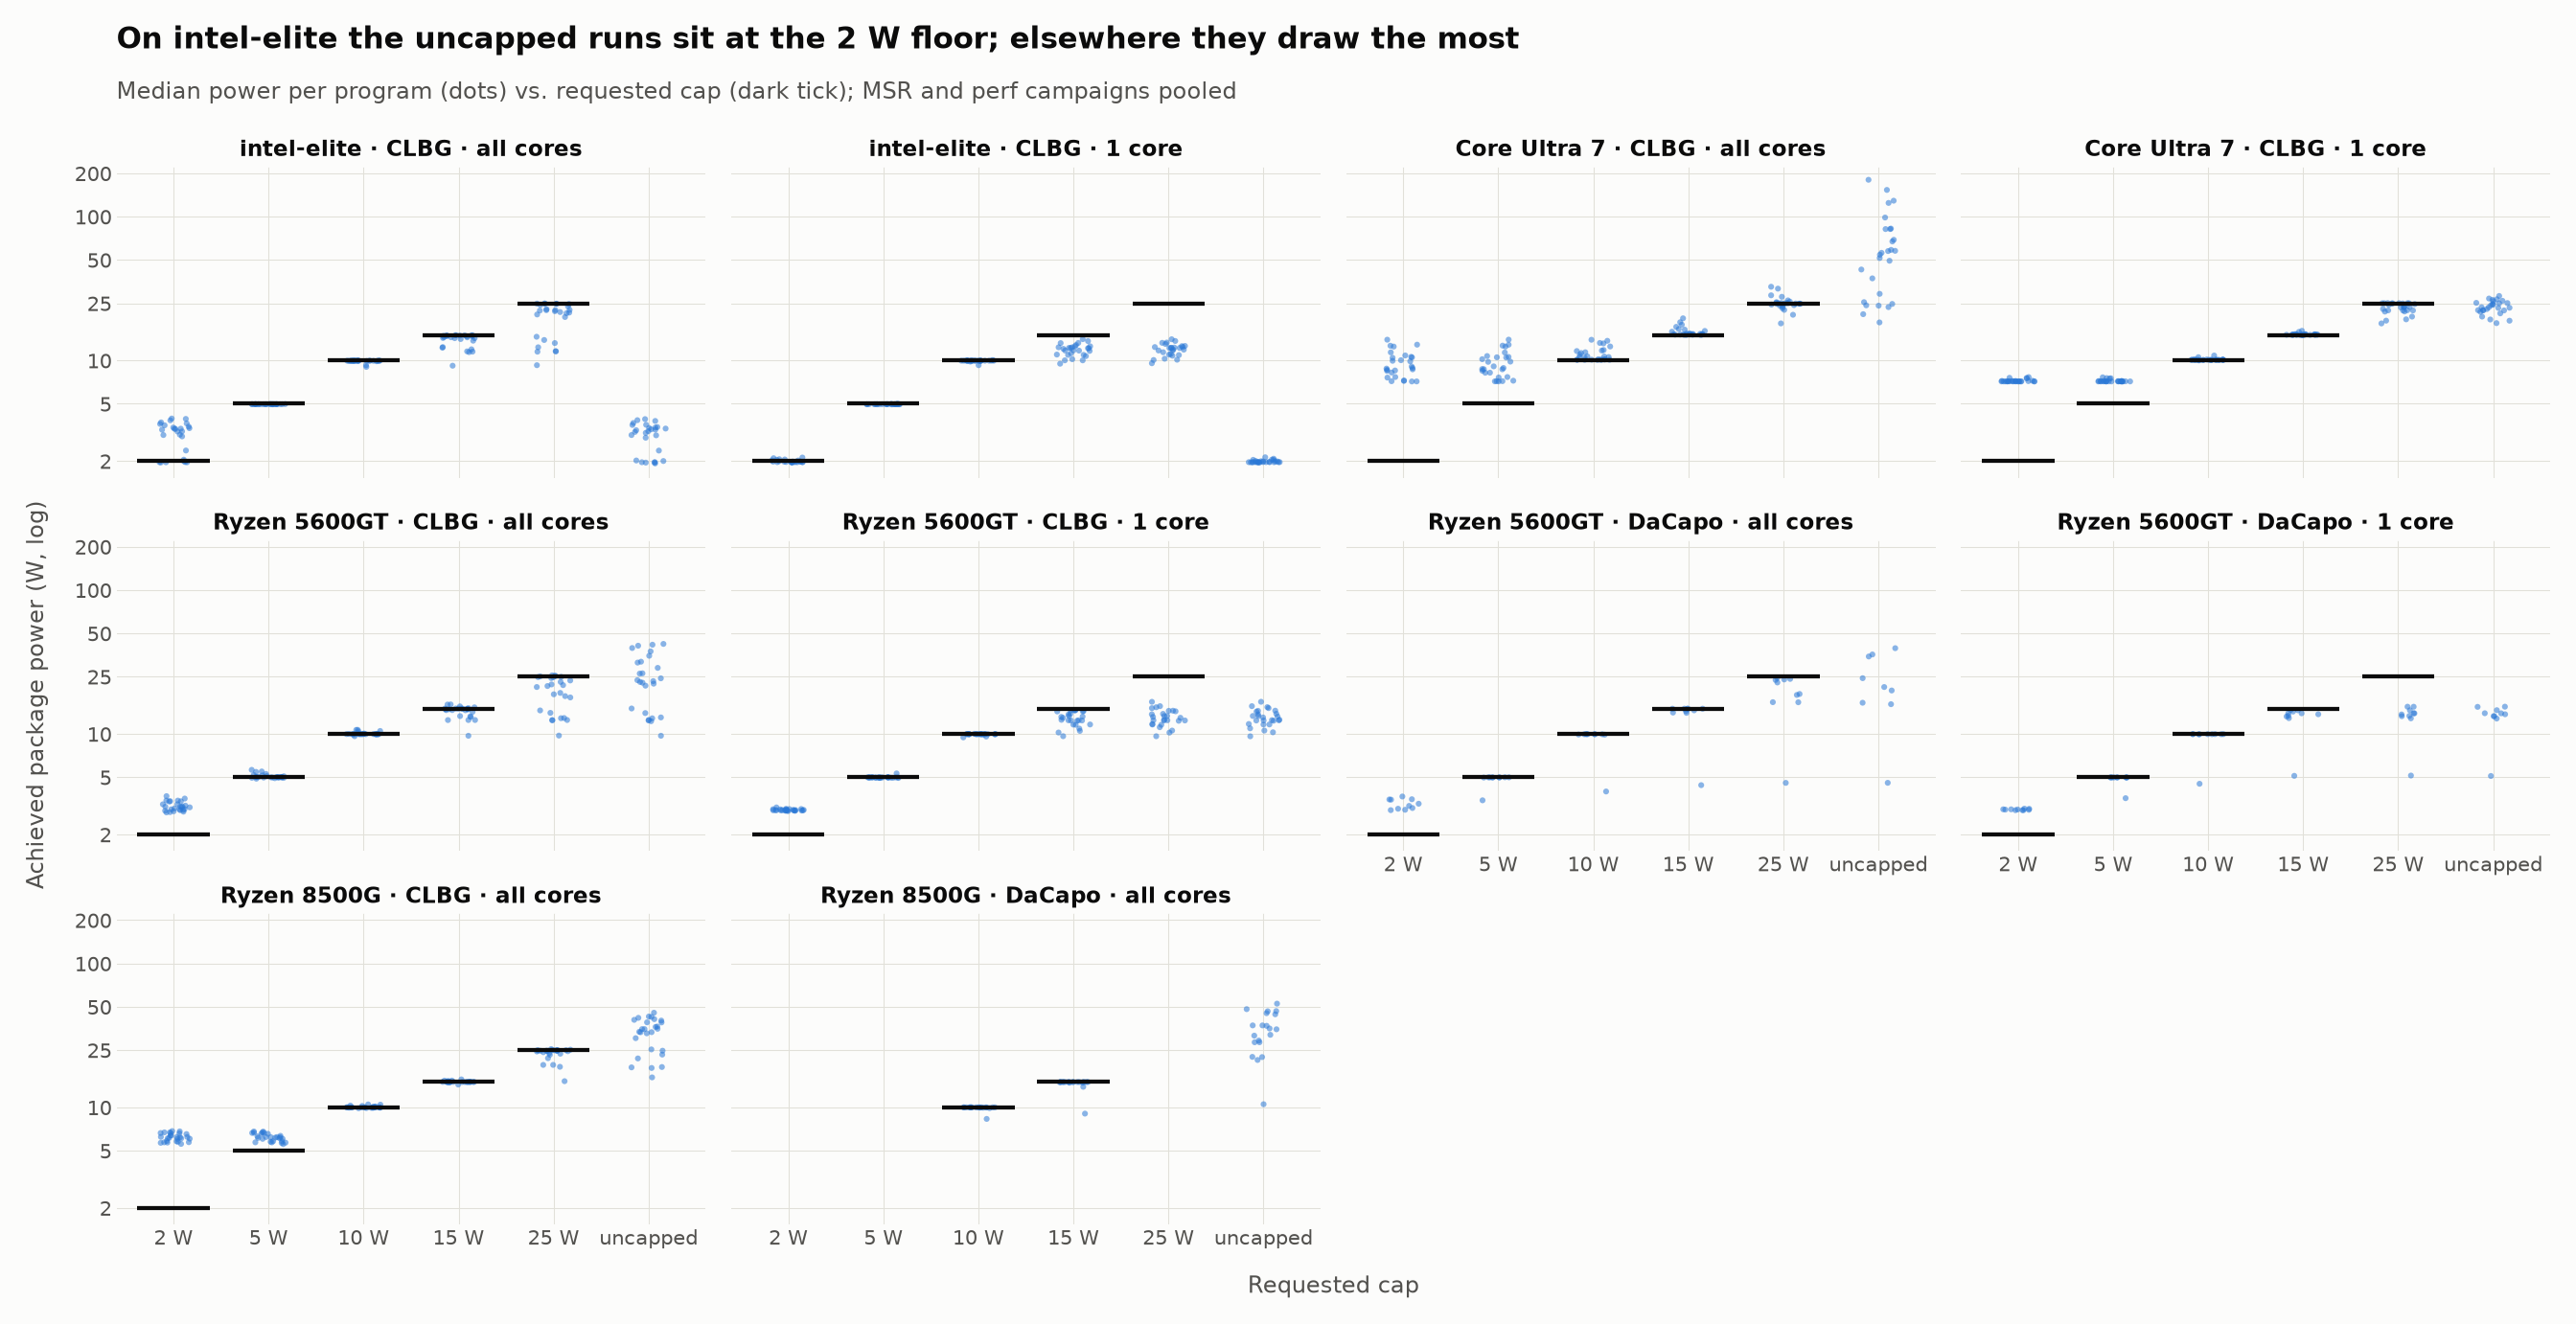

In [8]:
achieved = clean.group_by('setup', 'bench', 'cap', 'power_limit').agg(P=pl.col('P').median())
ticks = (achieved.select('setup', 'cap', 'power_limit').unique().filter(pl.col('power_limit') > 0)
                 .with_columns(x=pl.col('cap').to_physical().cast(pl.Float64) + 1))
(ggplot(achieved, aes('cap', 'P'))
 + geom_point(color=SERIES, alpha=0.55, size=1.3, stroke=0, position=position_jitter(width=0.18, height=0, random_state=1))
 + geom_segment(aes(x='x - 0.38', xend='x + 0.38', y='power_limit', yend='power_limit'), data=ticks, color=INK,
                size=0.9, inherit_aes=False)
 + facet_wrap('setup', ncol=4)
 + scale_y_log10(breaks=[1, 2, 5, 10, 25, 50, 100, 200])
 + labs(x='Requested cap', y='Achieved package power (W, log)',
        title='On intel-elite the uncapped runs sit at the 2 W floor; elsewhere they draw the most',
        subtitle='Median power per program (dots) vs. requested cap (dark tick); MSR and perf campaigns pooled')
 + base_theme(14, 7.2))

* 2 W  fica abaixo do piso do hardware em todas as máquinas (exceto no `intel-elite`)
* 5W fica abaixo do piso do hardware do Core Ultra 7 e no 8500G(~6/7 W).
* Com 1 núcleo, 15 W e 25 W quase nunca atuam.

### 2.2 Precisão

Um limite ≥ 25 % acima da potência máxima do programa não deveria mudar nada (razão = 1).

In [9]:
CELL_KEYS = ['machine', 'group', 'setup', 'campaign', 'cores', 'tool', 'baseline_ok', 'bench', 'power_limit', 'cap']
cell = clean.group_by(CELL_KEYS).agg(pl.col('E', 'T', 'EDP', 'P', 'temp_c').median(), n=pl.len(),
                                     E_runs=pl.col('E'), EDP_runs=pl.col('EDP'),
                                     P_max=pl.col('P').max())
base = (cell.filter(pl.col('power_limit') == -1, 'baseline_ok')
            .select('campaign', 'bench', E_base='E', T_base='T', EDP_base='EDP', P_base='P', P_base_max='P_max',
                    E_runs_base='E_runs', EDP_runs_base='EDP_runs'))


def cap_status(P='P', P_base='P_base', cap='power_limit'):
    # was the requested cap actually applied to this program?
    return (pl.when(pl.col(P_base) < 1.1 * pl.col(cap)).then(pl.lit('no effect'))
              .when(pl.col(P) > 1.1 * pl.col(cap)).then(pl.lit('not enforced'))
              .otherwise(pl.lit('applied')))


ratio = (cell.filter(pl.col('power_limit') != -1).join(base, on=['campaign', 'bench'])
             .with_columns(E_ratio=pl.col('E') / pl.col('E_base'), T_ratio=pl.col('T') / pl.col('T_base'),
                           EDP_ratio=pl.col('EDP') / pl.col('EDP_base'), status=cap_status()))

placebo = (ratio.filter(pl.col('power_limit') >= 1.25 * pl.col('P_base_max'))
                .group_by('campaign')
                .agg(cells=pl.len(), energy=gmean('E_ratio'), time=gmean('T_ratio'), EDP=gmean('EDP_ratio'),
                     EDP_p05=pl.col('EDP_ratio').quantile(0.05), EDP_p95=pl.col('EDP_ratio').quantile(0.95))
                .sort('campaign'))
placebo.select('campaign', 'cells', *[((pl.col(c) - 1) * 100).round(2).alias(f'{c} %')
                                      for c in ['energy', 'time', 'EDP', 'EDP_p05', 'EDP_p95']])

campaign,cells,energy %,time %,EDP %,EDP_p05 %,EDP_p95 %
"""Core Ultra 7 · CLBG · all cores · MSR""",1,-0.57,0.77,0.29,0.29,0.29
"""Core Ultra 7 · CLBG · all cores · perf""",1,-1.72,0.32,-1.39,-1.39,-1.39
"""Core Ultra 7 · CLBG · 1 core · MSR""",2,-0.57,-0.22,-0.76,-1.27,-0.24
"""Core Ultra 7 · CLBG · 1 core · perf""",3,0.46,0.12,0.57,-0.11,0.95
"""Ryzen 5600GT · CLBG · all cores · perf""",9,-0.11,-0.17,-0.07,-2.48,1.52
"""Ryzen 5600GT · CLBG · 1 core · perf""",33,-0.06,0.03,-0.01,-1.13,0.82
"""Ryzen 5600GT · DaCapo · all cores · perf""",5,-2.19,0.56,-1.76,-9.59,2.63
"""Ryzen 5600GT · DaCapo · 1 core · perf""",12,-0.75,0.21,-0.52,-0.79,1.18
"""Ryzen 8500G · CLBG · all cores · perf""",3,-0.24,-0.05,-0.37,-5.49,2.32


* 5600GT: desvio médio de −0.07 % e −0.01 % (antes, até ±2 %).
* 8500G (sem controle): −0.37 %, mas p05–p95 vai de −5.5 a +2.3 %.
* Num programa isolado, diferenças de ±2 % ainda são ruído.

Cells whose first 3 runs are >15 % slower than the other 17 ("slow start"): 11 of 1949


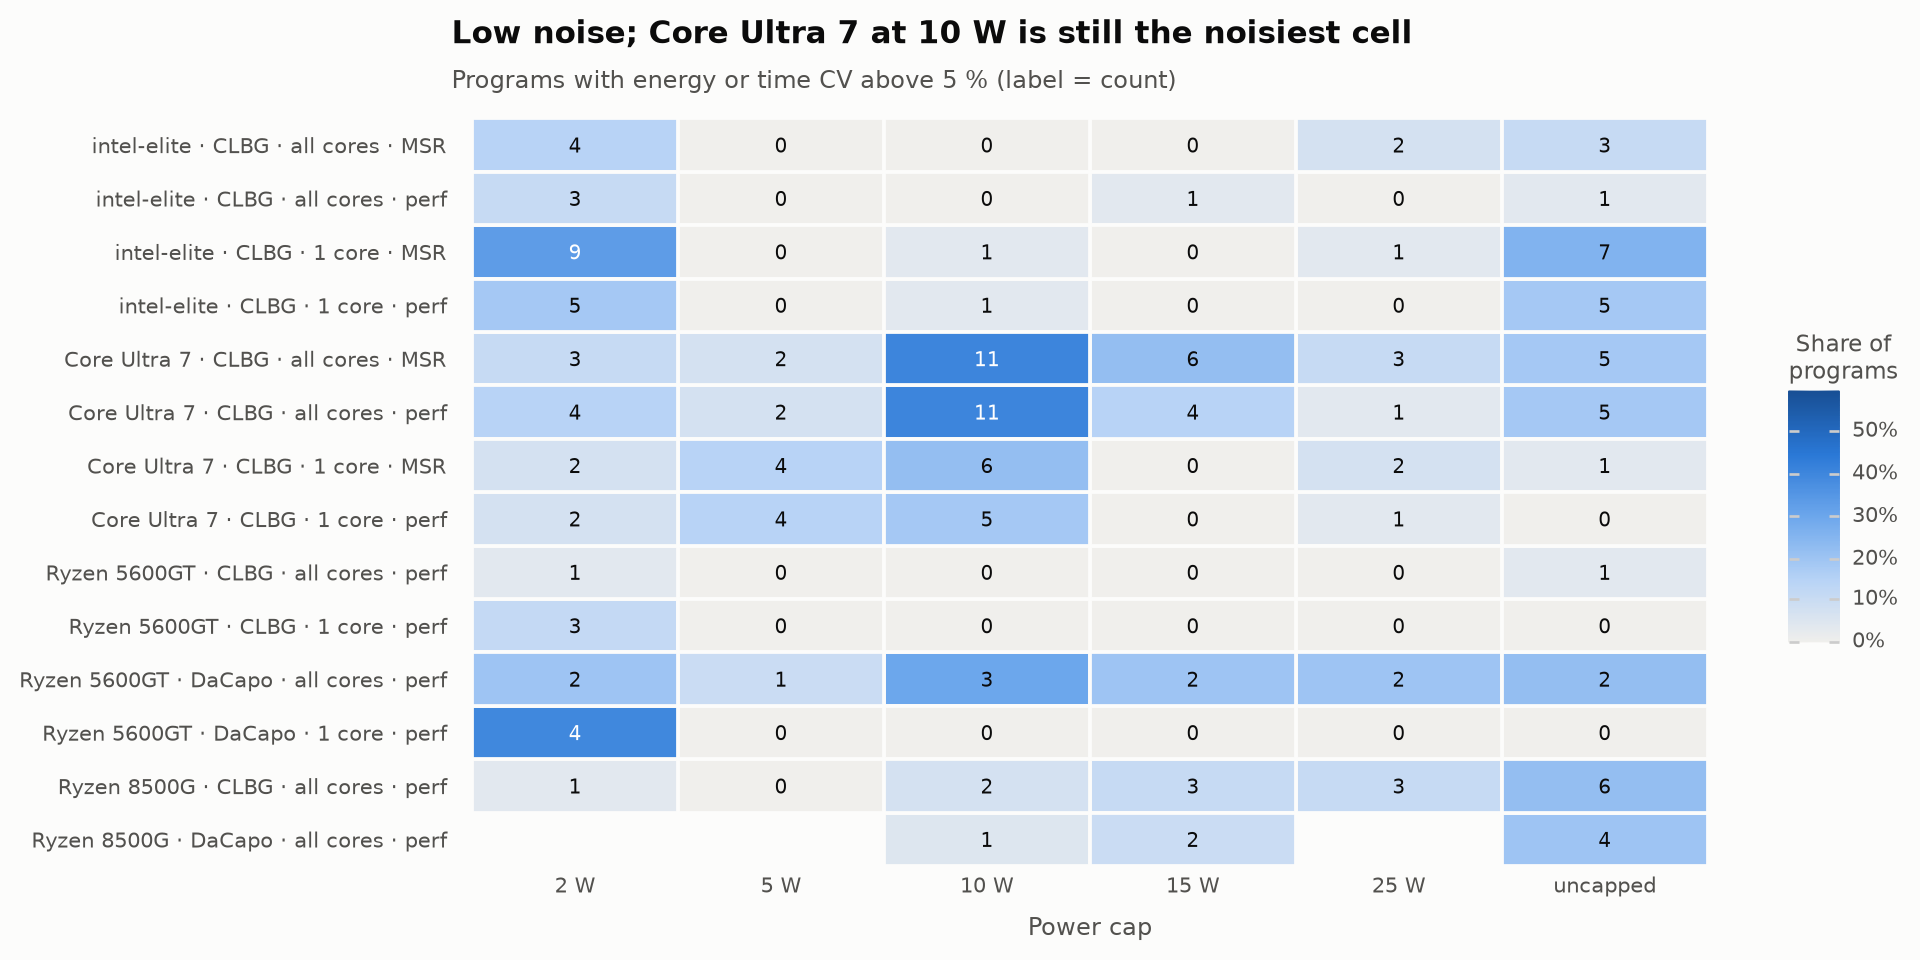

In [10]:
cell_noise = (clean.sort('run').group_by('campaign', 'bench', 'cap')
                   .agg(cv_E=pl.col('E').std() / pl.col('E').mean() * 100, cv_T=pl.col('T').std() / pl.col('T').mean() * 100,
                        slow_start=pl.col('T').head(3).median() / pl.col('T').slice(3).median()))
noise = (cell_noise.group_by('campaign', 'cap')
                   .agg(n=pl.len(), noisy=((pl.col('cv_E') > 5) | (pl.col('cv_T') > 5)).sum(),
                        slow=(pl.col('slow_start') > 1.15).sum())
                   .with_columns(share=pl.col('noisy') / pl.col('n'),
                                 txt=pl.when(pl.col('noisy') / pl.col('n') > 0.3).then(pl.lit('#ffffff')).otherwise(pl.lit(INK))))
print('Cells whose first 3 runs are >15 % slower than the other 17 ("slow start"):',
      noise['slow'].sum(), 'of', noise['n'].sum())
(ggplot(noise, aes('cap', 'campaign'))
 + geom_tile(aes(fill='share'), color=SURFACE, size=0.8)
 + geom_text(aes(label='noisy', color='txt'), size=7.5)
 + scale_color_identity()
 + scale_fill_gradientn(colors=SEQUENTIAL, limits=(0, 0.6), oob=squish, name='Share of\nprograms',
                        labels=lambda v: [f'{x:.0%}' for x in v])
 + scale_y_discrete(limits=CAMPAIGNS[::-1])
 + labs(x='Power cap', y='', title='Low noise; Core Ultra 7 at 10 W is still the noisiest cell',
        subtitle='Programs with energy or time CV above 5 % (label = count)')
 + base_theme(10, 5) + HEAT)

### 2.3 Registro da limpeza

In [11]:
pl.DataFrame(issues)

check,where,rows,action
"""program failed (ProgramError)""","""Ryzen 8500G · DaCapo: cassandra, h2o""",6,"""dropped"""
"""program failed (all zeros)""","""Ryzen 8500G · DaCapo: eclipse""",3,"""dropped"""
"""program failed (ProgramError)""","""Ryzen 5600GT · CLBG: binary-trees""",12,"""dropped"""
"""program failed (ProgramError)""","""Ryzen 5600GT · DaCapo: cassandra, h2o, pmd, tradebeans, tradesoap""",49,"""dropped"""
"""program failed (all zeros)""","""Ryzen 5600GT · DaCapo: eclipse, graphchi, jython, kafka, luindex, lusearch, spri…",1920,"""dropped"""
"""RAPL counter wraparound""","""data/single-measurements-perf-0-13-11-2026-23:57:36.csv, results/intel-CoreUltra…",2,"""+262 144 J (matches the cell power)"""
"""uncapped block inherited a ~2 W cap""","""intel-elite · CLBG · all cores · MSR, intel-elite · CLBG · all cores · perf, int…",2160,"""kept, excluded from comparisons against uncapped"""


### 2.4 Duração das campanhas

**Medido** = soma do tempo de relógio de todas as execuções (sem a espera de resfriamento e a
compilação). **Decorrido** = do início da campanha ao início da próxima na mesma máquina. Tabela em horas.

Measured time per machine: intel-elite 40.0 h, Ryzen 5600GT 36.9 h, Core Ultra 7 36.7 h, Ryzen 8500G 6.5 h


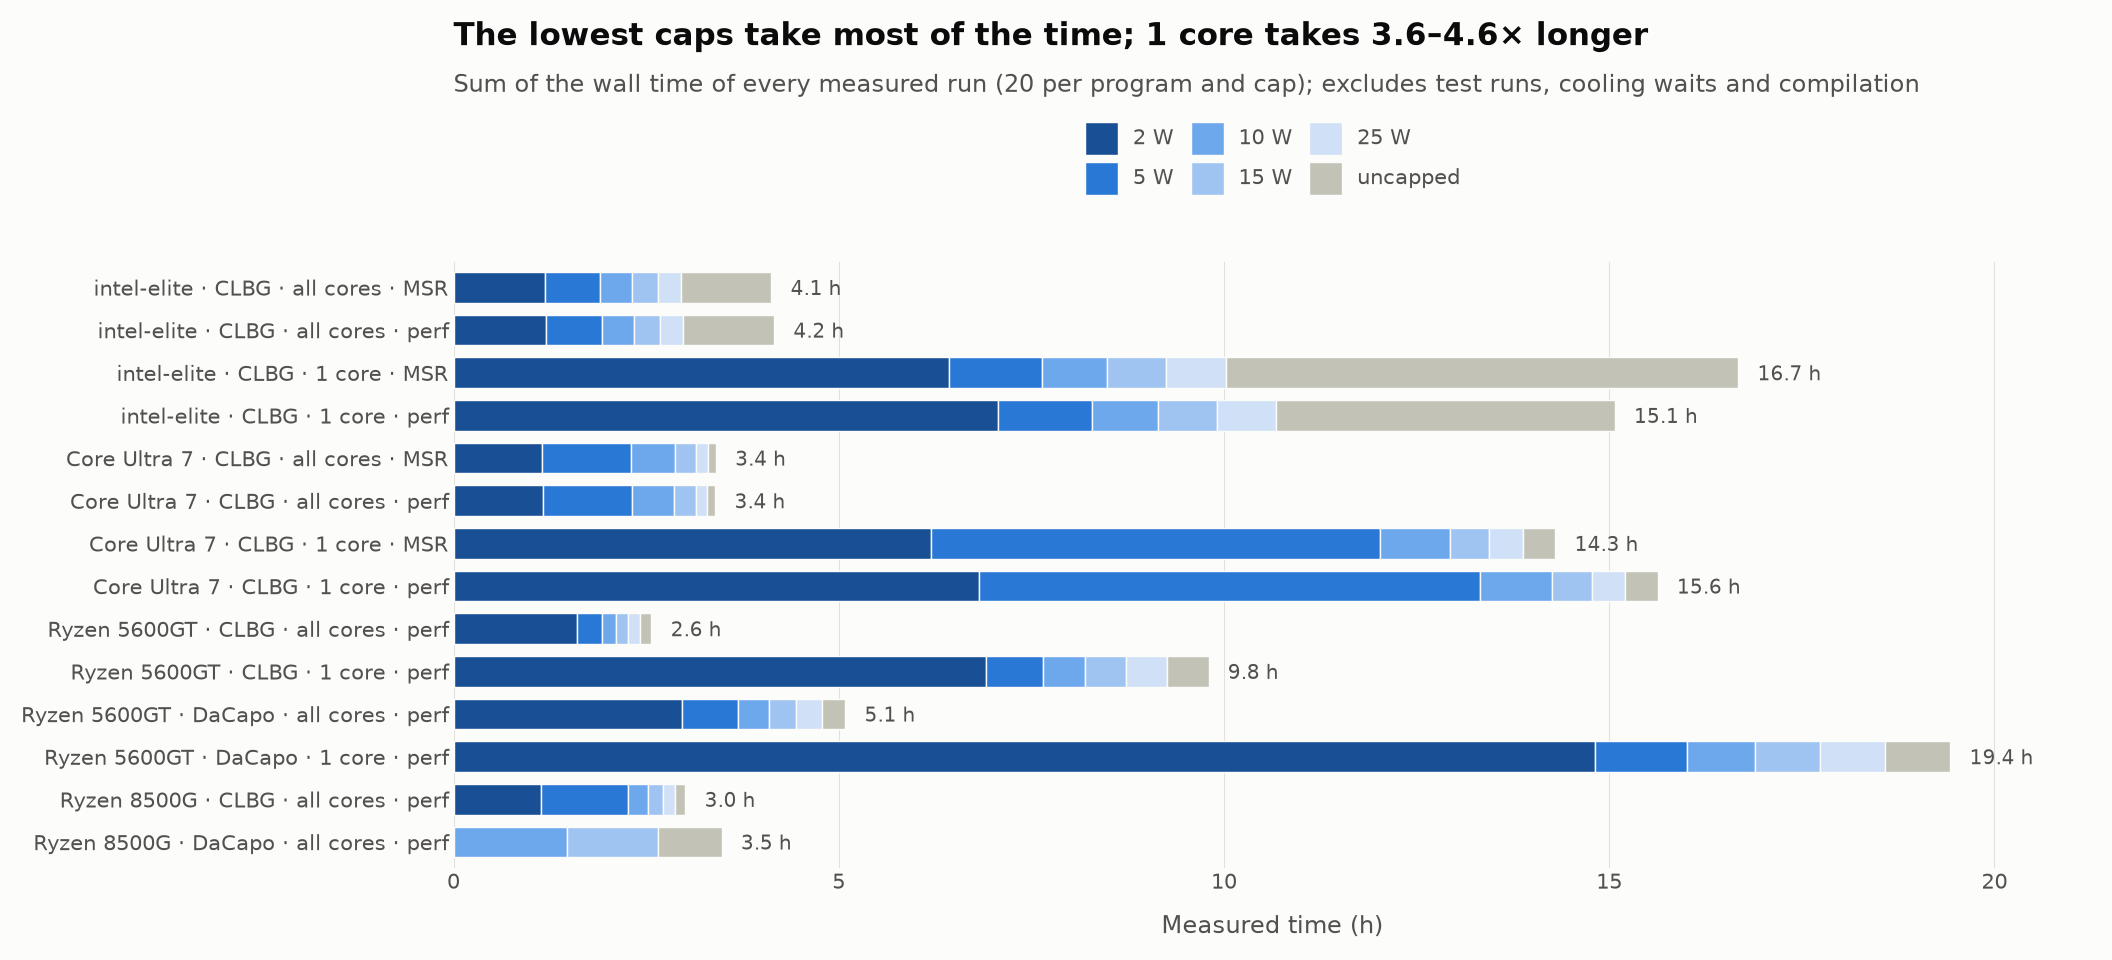

In [12]:
# measured time: sum of the wall time of every run kept (failed programs add nothing)
dur = clean.group_by('campaign', 'cap').agg(h=pl.col('T').sum() / 3600)
dur_total = (dur.group_by('campaign').agg(total=pl.col('h').sum())
                .with_columns(label=pl.format('{} h', pl.col('total').round(1))))
CAP_COLOR = dict(zip(CAP_ORDER, ['#184f95', '#2a78d6', '#6da7ec', '#9fc4f1', '#cfe0f7', AXIS]))
print('Measured time per machine:', ', '.join(f'{m} {h:.1f} h' for m, h in
      clean.group_by('machine_label').agg(h=pl.col('T').sum() / 3600).sort('h', descending=True).iter_rows()))
(ggplot(dur, aes('campaign', 'h', fill='cap'))
 + geom_col(width=0.72, color=SURFACE, size=0.3, position=position_stack(reverse=True))
 + geom_text(aes(x='campaign', y='total', label='label'), data=dur_total, inherit_aes=False, ha='left',
             nudge_y=0.25, size=7.5, color=INK2)
 + coord_flip()
 + scale_x_discrete(limits=CAMPAIGNS[::-1])
 + scale_y_continuous(breaks=[0, 5, 10, 15, 20], expand=(0, 0, 0.08, 0))
 + scale_fill_manual(values=CAP_COLOR, breaks=CAP_ORDER)
 + labs(x='', y='Measured time (h)', title='The lowest caps take most of the time; 1 core takes 3.6–4.6× longer',
        subtitle='Sum of the wall time of every measured run (20 per program and cap); excludes test runs, cooling waits and compilation')
 + base_theme(11, 5) + theme(legend_position='top', legend_title=element_blank(), panel_grid_major_y=element_blank()))

In [13]:
# elapsed: from the start of a campaign (file name) to the start of the next one on the same machine
starts = (clean.select('campaign', 'machine', 'source').unique()
               .with_columns(start=pl.col('source').str.extract(r'(\d{2}-\d{2}-\d{4}-\d{2}:\d{2}:\d{2})')
                                   .str.strptime(pl.Datetime, '%d-%m-%Y-%H:%M:%S'))
               .sort('machine', 'start')
               .with_columns(elapsed=(pl.col('start').shift(-1).over('machine') - pl.col('start')).dt.total_seconds() / 3600))
(dur.sort('campaign', 'cap').pivot(on='cap', index='campaign', values='h')
    .with_columns(measured=pl.sum_horizontal(CAP_ORDER))
    .join(starts.select('campaign', 'start', 'elapsed'), on='campaign')
    .sort('campaign')
    .select('campaign', *CAP_ORDER, 'measured', 'elapsed', 'start')
    .with_columns(cs.float().round(2)))

campaign,2 W,5 W,10 W,15 W,25 W,uncapped,measured,elapsed,start
"""intel-elite · CLBG · all cores · MSR""",1.18,0.72,0.41,0.34,0.3,1.18,4.13,4.72,2026-11-13 13:40:59
"""intel-elite · CLBG · all cores · perf""",1.2,0.74,0.42,0.34,0.29,1.18,4.16,5.56,2026-11-13 18:24:09
"""intel-elite · CLBG · 1 core · MSR""",6.44,1.2,0.84,0.77,0.77,6.65,16.67,18.12,2026-11-13 23:57:36
"""intel-elite · CLBG · 1 core · perf""",7.07,1.22,0.85,0.77,0.77,4.39,15.07,null,2026-11-14 18:04:49
"""Core Ultra 7 · CLBG · all cores · MSR""",1.15,1.15,0.57,0.28,0.15,0.1,3.41,3.76,2026-11-13 13:37:44
"""Core Ultra 7 · CLBG · all cores · perf""",1.16,1.15,0.55,0.28,0.15,0.1,3.4,4.54,2026-11-13 17:23:08
"""Core Ultra 7 · CLBG · 1 core · MSR""",6.2,5.82,0.91,0.51,0.43,0.42,14.3,15.15,2026-11-13 21:55:27
"""Core Ultra 7 · CLBG · 1 core · perf""",6.82,6.49,0.94,0.52,0.43,0.42,15.63,null,2026-11-14 13:04:27
"""Ryzen 5600GT · CLBG · all cores · perf""",1.6,0.32,0.18,0.16,0.15,0.15,2.57,3.8,2026-11-13 12:58:38
"""Ryzen 5600GT · CLBG · 1 core · perf""",6.91,0.73,0.55,0.53,0.53,0.53,9.8,12.48,2026-11-14 07:01:18


* 1 núcleo leva 3.6–4.6× mais que todos os núcleos (Ryzen DaCapo: 5.1 h → 19.4 h).
* Os limites mais baixos dominam: 2 W (e 5 W no Core Ultra 7) somam 58–85 % do tempo no 5600GT e no Core Ultra 7, e
  são justamente os que não são respeitados. No 8500G, 2 W e 5 W (os dois no piso) somam 75 %.
* `intel-elite`: o bloco sem limite levou o mesmo que o de 2 W (rodou sob o limite herdado). Rodado de novo, deve
  levar perto do de 25 W (~0.3 h com todos os núcleos, ~0.8 h com 1 núcleo, por ferramenta).
* Decorrido fica 6–34 % acima do medido nas máquinas Intel (8500G: 11 %). No 5600GT, DaCapo com todos os núcleos tem
  14.2 h decorridas para 5.1 h medidas: os 8 programas que gravam 0 J em 0 ms rodaram (~8 h), mas sem tempo registrado.
  A última campanha de cada máquina não tem decorrido.

## 3 · Bootstrap

IC 95 % (2000 reamostragens) da razão com limite / sem limite de cada programa. **better** / **worse** = IC inteiro
abaixo / acima de 1; senão, **tie**. Intel: campanhas MSR e perf combinadas; o veredito só vale se as duas concordam.

In [14]:
def boot_ci(capped, uncapped, rng):
    a, b = np.asarray(capped), np.asarray(uncapped)
    ma = np.median(a[rng.integers(0, len(a), (B, len(a)))], axis=1)
    mb = np.median(b[rng.integers(0, len(b), (B, len(b)))], axis=1)
    return np.quantile(ma / mb, [0.025, 0.975])


def verdict(lo, hi):
    return pl.when(pl.col(hi) < 1).then(pl.lit('better')).when(pl.col(lo) > 1).then(pl.lit('worse')).otherwise(pl.lit('tie'))


def agree(col):
    return pl.when(pl.col(col).n_unique() == 1).then(pl.col(col).first()).otherwise(pl.lit('tie'))


ratio = ratio.sort(CELL_KEYS)
keys = list(ratio.select('campaign', 'bench', 'power_limit').cast(pl.String).iter_rows())
ci = {m: np.array([boot_ci(a, b, key_rng(m, *k)) for a, b, k in zip(ratio[f'{m}_runs'], ratio[f'{m}_runs_base'], keys)])
      for m in ['E', 'EDP']}
ratio = (ratio.with_columns(E_lo=ci['E'][:, 0], E_hi=ci['E'][:, 1], EDP_lo=ci['EDP'][:, 0], EDP_hi=ci['EDP'][:, 1])
              .with_columns(E_verdict=verdict('E_lo', 'E_hi'), EDP_verdict=verdict('EDP_lo', 'EDP_hi'))
              .drop(cs.ends_with('_runs', '_runs_base')))
setup_ratio = (ratio.group_by('machine', 'group', 'setup', 'cores', 'bench', 'power_limit', 'cap')
                    .agg(gmean('E_ratio'), gmean('T_ratio'), gmean('EDP_ratio'), gmean('P'), gmean('P_base'),
                         campaigns=pl.len(), E_verdict=agree('E_verdict'), EDP_verdict=agree('EDP_verdict'))
                    .with_columns(status=cap_status())
                    .sort('setup', 'bench', 'power_limit'))
print(f'{ratio.height} ratios per campaign and {setup_ratio.height} per setup (program, cap)')
# programs where the cap was applied / programs, per setup and cap
(setup_ratio.group_by('setup', 'cap').agg(applied=(pl.col('status') == 'applied').sum(), n=pl.len())
            .sort('setup', 'cap').with_columns(v=pl.format('{}/{}', 'applied', 'n'))
            .pivot(on='cap', index='setup', values='v'))

1070 ratios per campaign and 800 per setup (program, cap)


setup,2 W,5 W,10 W,15 W,25 W
"""Core Ultra 7 · CLBG · all cores""","""0/27""","""0/27""","""17/27""","""23/27""","""16/27"""
"""Core Ultra 7 · CLBG · 1 core""","""0/27""","""0/27""","""27/27""","""27/27""","""1/27"""
"""Ryzen 5600GT · CLBG · all cores""","""0/26""","""25/26""","""25/26""","""18/26""","""9/26"""
"""Ryzen 5600GT · CLBG · 1 core""","""0/26""","""26/26""","""22/26""","""1/26""","""0/26"""
"""Ryzen 5600GT · DaCapo · all cores""","""0/9""","""8/9""","""8/9""","""6/9""","""3/9"""
"""Ryzen 5600GT · DaCapo · 1 core""","""0/10""","""9/10""","""9/10""","""0/10""","""0/10"""
"""Ryzen 8500G · CLBG · all cores""","""0/27""","""0/27""","""27/27""","""26/27""","""19/27"""
"""Ryzen 8500G · DaCapo · all cores""",null,null,"""19/20""","""19/20""",null


Programas em que o limite atuou / total. 2 W (e 5 W no Core Ultra 7 e no 8500G) fica abaixo do piso; com 1 núcleo, 15–25 W não têm efeito.

## 4 · O limite vale a pena?

### 4.1 Visão geral

`intel-elite` fora (sem execução sem limite válida).

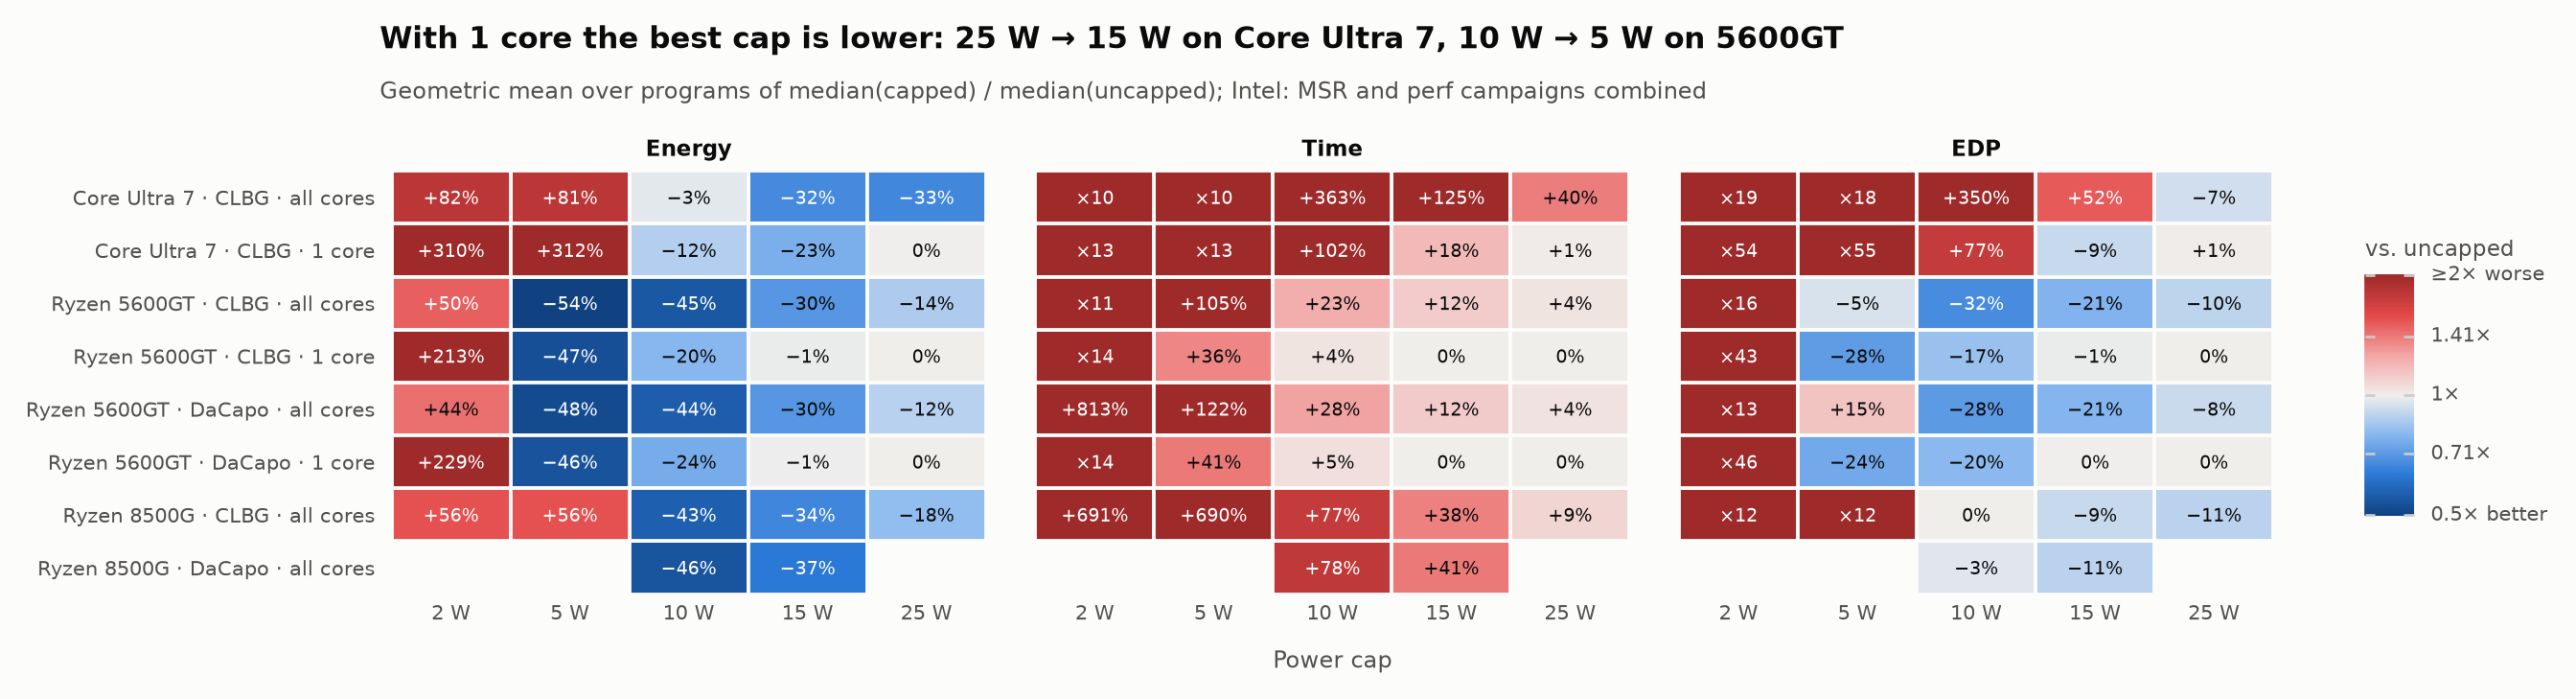

In [15]:
overview = (setup_ratio.group_by('setup', 'cap')
                       .agg(Energy=gmean('E_ratio'), Time=gmean('T_ratio'), EDP=gmean('EDP_ratio'))
                       .unpivot(index=['setup', 'cap'], variable_name='metric', value_name='ratio')
                       .with_columns(metric=pl.col('metric').cast(pl.Enum(['Energy', 'Time', 'EDP'])),
                                     l2=pl.col('ratio').log(2).clip(-1, 1), label=pct_text('ratio'))
                       .with_columns(txt=tile_text_color()))
VALID_SETUPS = [s for s in SETUPS if s in set(overview['setup'].cast(pl.String))]
(ggplot(overview, aes('cap', 'setup'))
 + geom_tile(aes(fill='l2'), color=SURFACE, size=0.8)
 + geom_text(aes(label='label', color='txt'), size=7)
 + scale_color_identity()
 + ratio_fill('vs. uncapped')
 + scale_y_discrete(limits=VALID_SETUPS[::-1])
 + facet_wrap('metric', ncol=3)
 + labs(x='Power cap', y='', title='With 1 core the best cap is lower: 25 W → 15 W on Core Ultra 7, 10 W → 5 W on 5600GT',
        subtitle='Geometric mean over programs of median(capped) / median(uncapped); Intel: MSR and perf campaigns combined')
 + base_theme(14, 3.8) + HEAT)

### 4.2 Por programa

**Negrito** = melhor limite do programa; cinza = empate; ○ = limite sem efeito; △ = limite não respeitado.

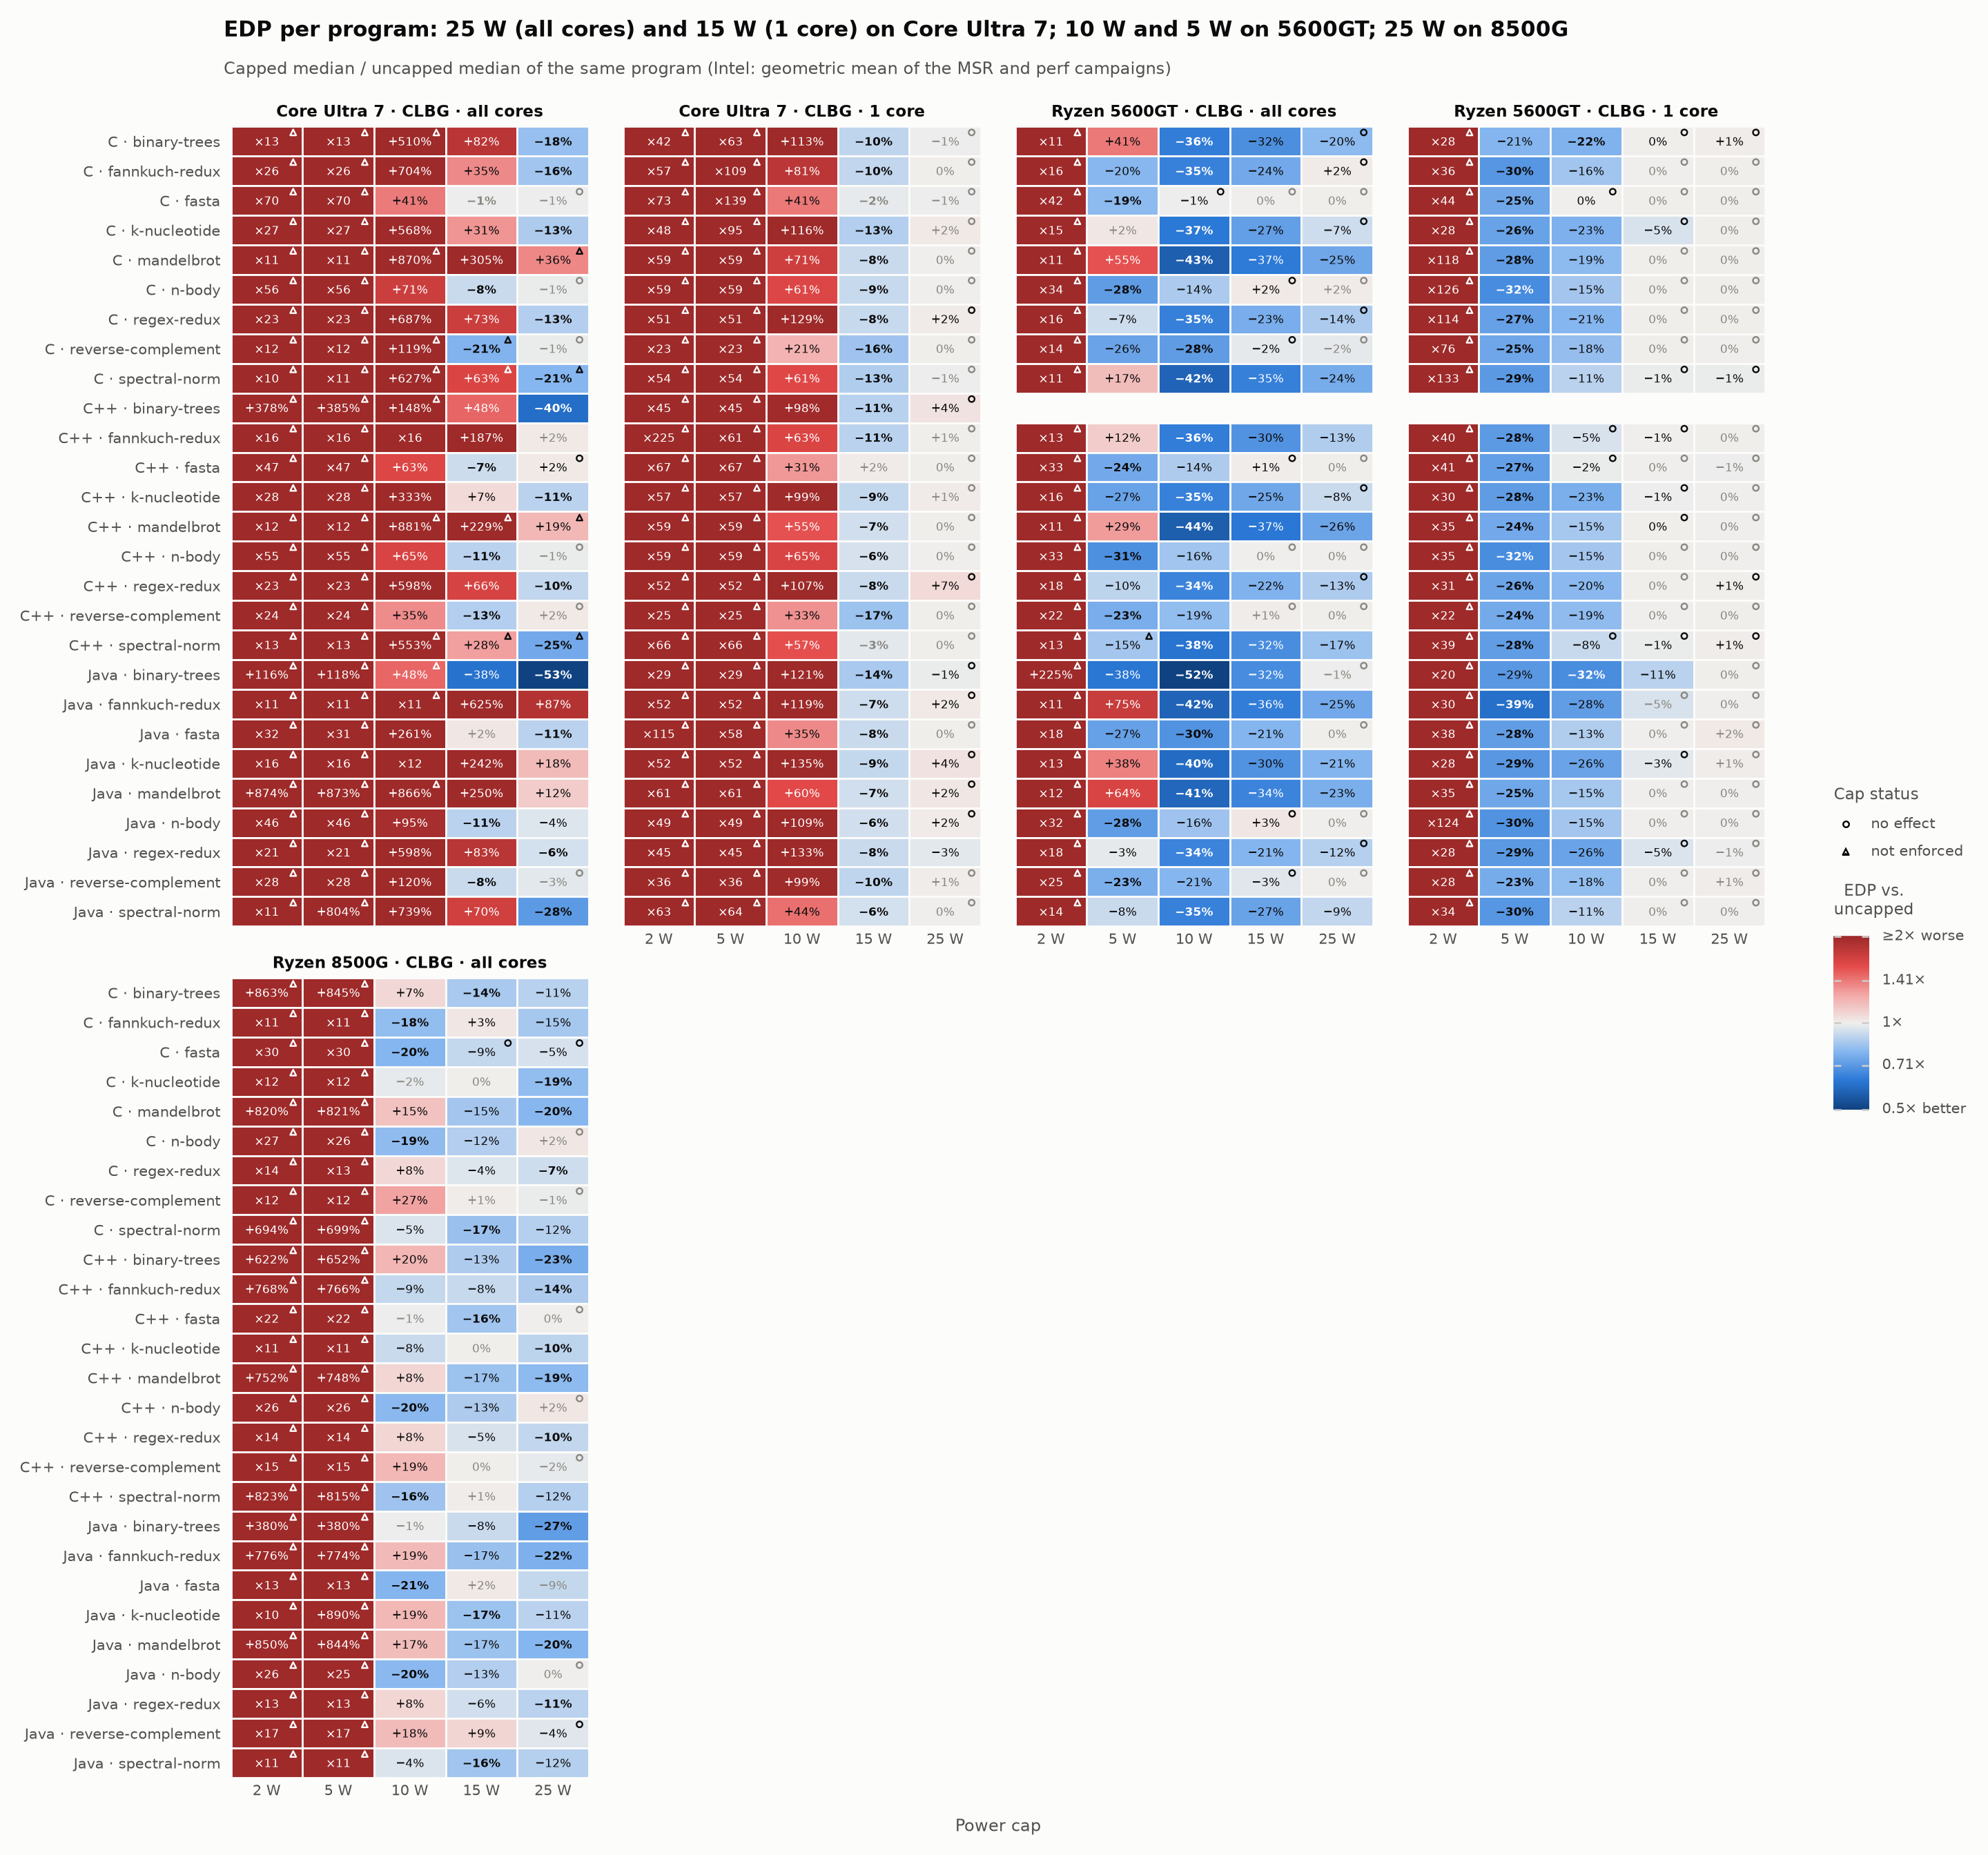

In [16]:
def bench_heatmap(metric, setups, title, ncol, size):
    r = f'{metric}_ratio'
    d = (setup_ratio.filter(pl.col('setup').cast(pl.String).is_in(setups))
                    .with_columns(setup=pl.col('setup').cast(pl.String).cast(pl.Enum(setups)),
                                  l2=pl.col(r).log(2).clip(-1, 1), label=pct_text(r))
                    .with_columns(best=(pl.col(r) == pl.col(r).filter(pl.col('status') != 'no effect')
                                                                .min().over('setup', 'bench'))
                                       & (pl.col(r) < 1) & (pl.col('status') != 'no effect'),
                                  txt=pl.when(pl.col('l2').abs() > 0.55).then(pl.lit('#ffffff'))
                                        .when(pl.col(f'{metric}_verdict') == 'tie').then(pl.lit(MUTED))
                                        .otherwise(pl.lit(INK))))
    benches = [b for b in BENCHES if b in set(d['bench'].cast(pl.String))]
    ypos = {b: float(len(benches) - i) for i, b in enumerate(benches)}
    marks = (d.filter(pl.col('status') != 'applied')
              .with_columns(mx=pl.col('cap').to_physical().cast(pl.Float64) + 1.37,
                            my=pl.col('bench').cast(pl.String).replace_strict(ypos, return_dtype=pl.Float64) + 0.3))
    return (ggplot(d, aes('cap', 'bench'))
            + geom_tile(aes(fill='l2'), color=SURFACE, size=0.6)
            + geom_text(aes(label='label', color='txt'), data=d.filter(~pl.col('best')), size=6.2)
            + geom_text(aes(label='label', color='txt'), data=d.filter('best'), size=6.2, fontweight='bold')
            + geom_point(aes(x='mx', y='my', shape='status', color='txt'), data=marks, size=1.3, fill='none',
                         stroke=0.5, inherit_aes=False)
            + scale_shape_manual(values={'no effect': 'o', 'not enforced': '^'}, name='Cap status')
            + scale_color_identity()
            + ratio_fill(f'{"Energy" if metric == "E" else metric} vs.\nuncapped')
            + scale_y_discrete(limits=benches[::-1])
            + facet_wrap('setup', ncol=ncol)
            + labs(x='Power cap', y='', title=title,
                   subtitle='Capped median / uncapped median of the same program (Intel: geometric mean of the MSR and perf campaigns)')
            + base_theme(*size) + HEAT)


CLBG_SETUPS = [s for s in VALID_SETUPS if 'CLBG' in s]
DACAPO_SETUPS = [s for s in VALID_SETUPS if 'DaCapo' in s]
bench_heatmap('EDP', CLBG_SETUPS, 'EDP per program: 25 W (all cores) and 15 W (1 core) on Core Ultra 7; '
              '10 W and 5 W on 5600GT; 25 W on 8500G', ncol=4, size=(15, 14))

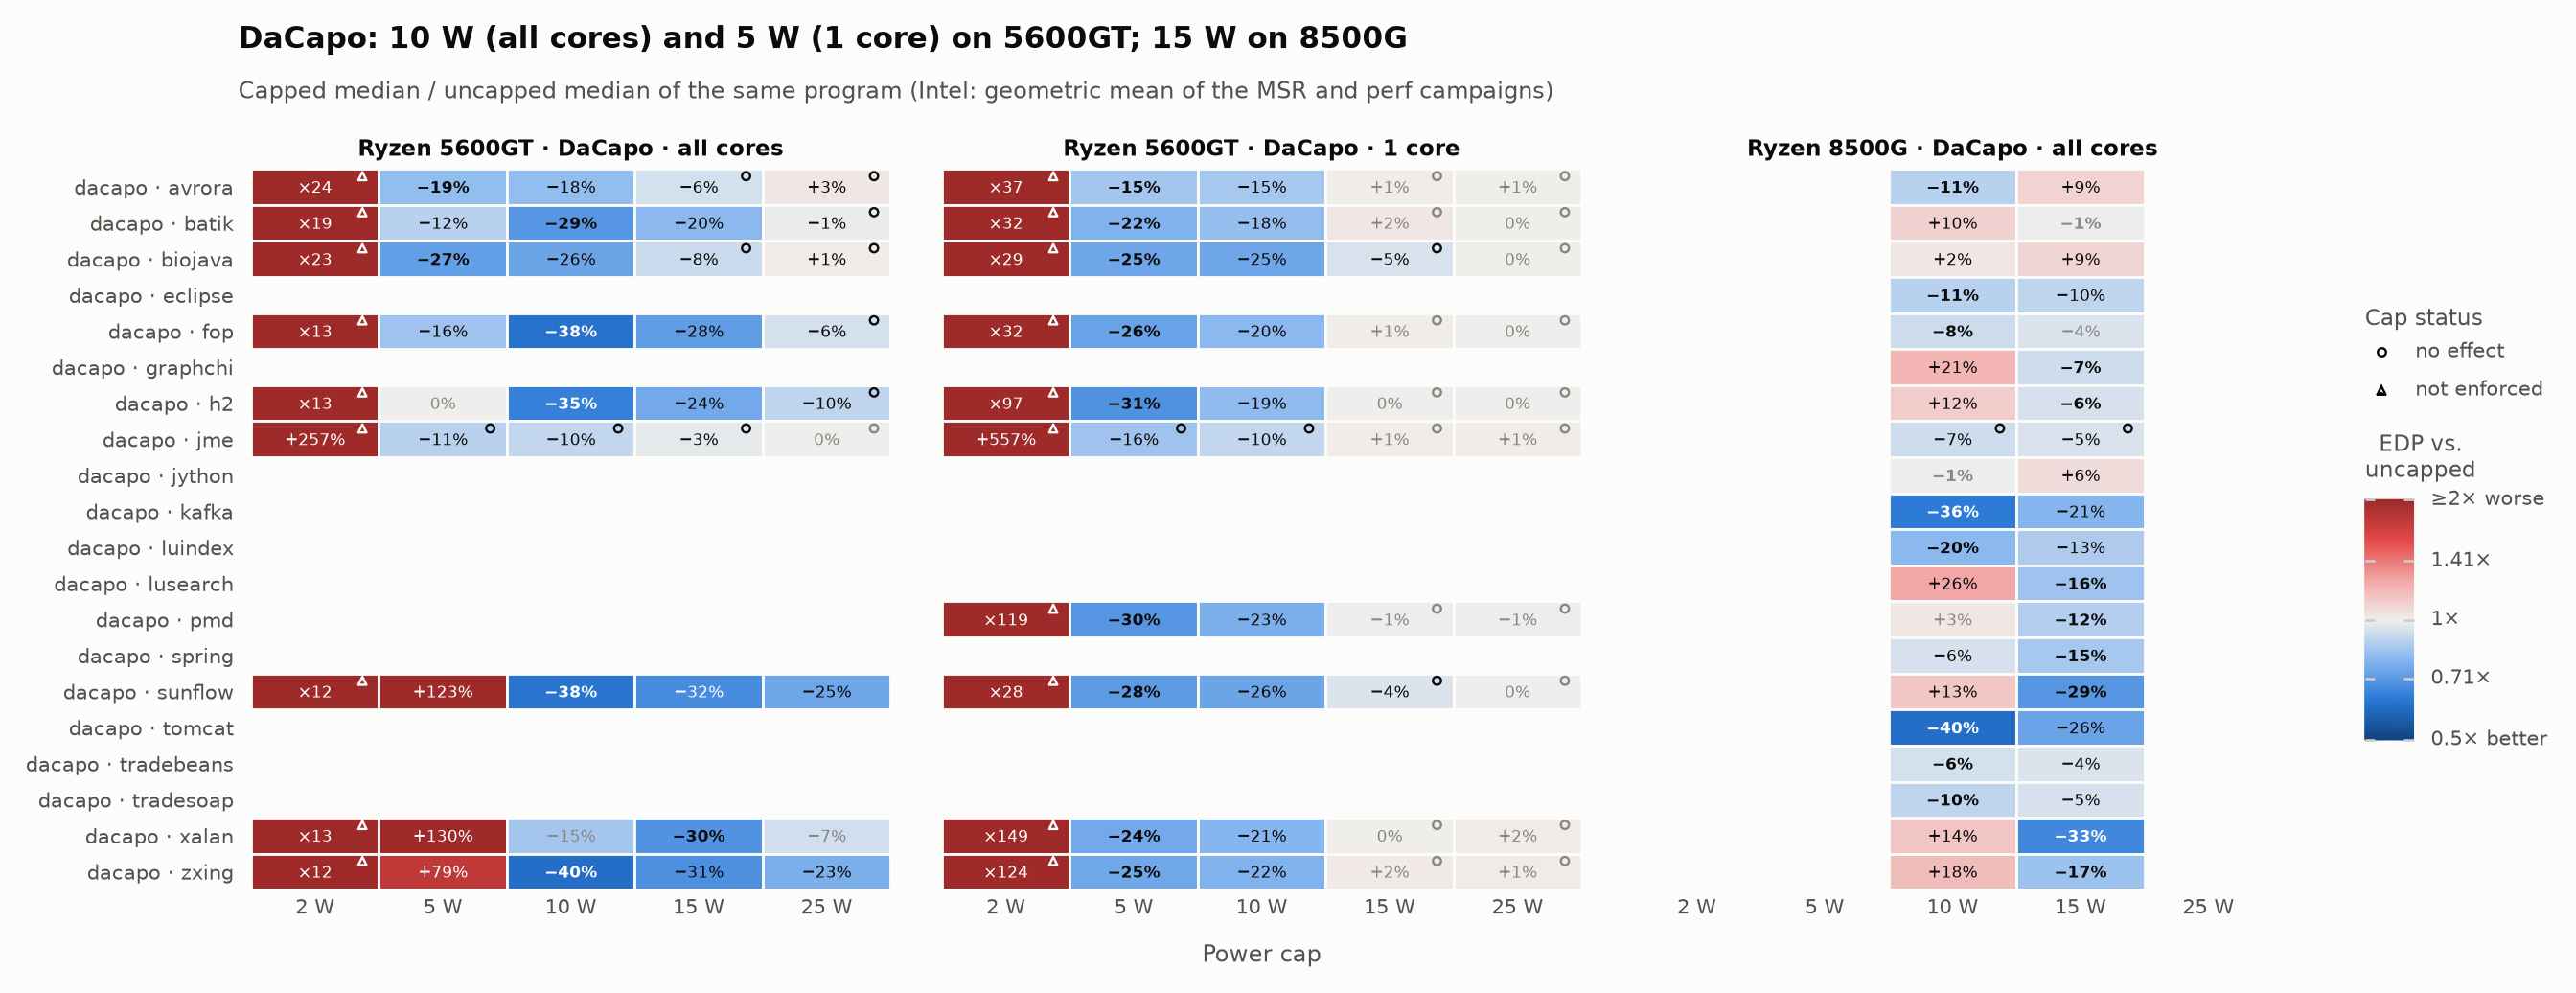

In [17]:
bench_heatmap('EDP', DACAPO_SETUPS, 'DaCapo: 10 W (all cores) and 5 W (1 core) on 5600GT; 15 W on 8500G',
              ncol=3, size=(14, 5.4))

### 4.3 Resumo por cenário

Melhor limite de cada cenário, com IC 95 % sobre programas. `worth_it` = IC inteiro abaixo de −2 %.

In [18]:
def gm_ci(values, rng):
    x = np.log(np.asarray(values))
    return np.exp(np.quantile(x[rng.integers(0, len(x), (B, len(x)))].mean(axis=1), [0.025, 0.975]))


per_cap = (setup_ratio.group_by('setup', 'power_limit', 'cap', maintain_order=True)
                      .agg(programs=pl.len(), energy=gmean('E_ratio'), time=gmean('T_ratio'), EDP=gmean('EDP_ratio'),
                           EDP_values=pl.col('EDP_ratio'),
                           better=(pl.col('EDP_verdict') == 'better').sum(), tie=(pl.col('EDP_verdict') == 'tie').sum(),
                           worse=(pl.col('EDP_verdict') == 'worse').sum(),
                           applied=(pl.col('status') == 'applied').sum(),
                           EDP_applied=pl.col('EDP_ratio').filter(pl.col('status') == 'applied').log().mean().exp())
                      .sort('setup', 'power_limit'))
edp_ci = np.array([gm_ci(v, key_rng('EDP', s, w)) for v, s, w in
                   zip(per_cap['EDP_values'], per_cap['setup'].cast(pl.String), per_cap['power_limit'])])
per_cap = (per_cap.drop('EDP_values').with_columns(EDP_lo=edp_ci[:, 0], EDP_hi=edp_ci[:, 1])
                  .with_columns(worth_it=pl.col('EDP_hi') < 0.98))
best_edp = per_cap.sort('EDP').group_by('setup', maintain_order=True).first().sort('setup')
best_edp.select('setup', pl.col('cap').alias('best_EDP_cap'), *as_pct('EDP', 'EDP_lo', 'EDP_hi', 'energy', 'time'),
                'better', 'tie', 'worse', 'worth_it', pl.format('{}/{}', 'applied', 'programs').alias('applied'),
                *as_pct('EDP_applied'))

setup,best_EDP_cap,EDP %,EDP_lo %,EDP_hi %,energy %,time %,better,tie,worse,worth_it,applied,EDP_applied %
"""Core Ultra 7 · CLBG · all cores""","""25 W""",-6.6,-14.8,2.6,-33.3,40.1,14,7,6,false,"""16/27""",-10.4
"""Core Ultra 7 · CLBG · 1 core""","""15 W""",-8.7,-10.2,-7.2,-22.9,18.4,24,3,0,true,"""27/27""",-8.7
"""Ryzen 5600GT · CLBG · all cores""","""10 W""",-32.4,-36.4,-27.9,-45.2,23.4,26,0,0,true,"""25/26""",-33.4
"""Ryzen 5600GT · CLBG · 1 core""","""5 W""",-27.8,-29.2,-26.6,-47.1,36.4,26,0,0,true,"""26/26""",-27.8
"""Ryzen 5600GT · DaCapo · all cores""","""10 W""",-28.5,-34.5,-21.7,-43.9,27.6,8,1,0,true,"""8/9""",-30.5
"""Ryzen 5600GT · DaCapo · 1 core""","""5 W""",-24.4,-27.2,-21.3,-46.4,40.9,10,0,0,true,"""9/10""",-25.3
"""Ryzen 8500G · CLBG · all cores""","""25 W""",-11.3,-14.3,-8.3,-18.4,9.0,20,7,0,true,"""19/27""",-15.3
"""Ryzen 8500G · DaCapo · all cores""","""15 W""",-10.8,-16.0,-6.0,-36.8,41.1,14,3,3,true,"""19/20""",-11.1


* **5600GT:** 10 W (todos os núcleos) e 5 W (1 núcleo) dão −24 a −32 % de EDP; nenhum programa piora (um empate, no
  DaCapo com todos os núcleos).
* **Core Ultra 7:** com todos os núcleos, 25 W dá −7 %, mas não é significativo (6 programas pioram). Com 1 núcleo,
  15 W dá −9 %.
* **8500G (sem controle):** 25 W no CLBG (−11 %, nenhum programa piora) e 15 W no DaCapo (−11 %, 3 de 20 pioram).

#### Teste pareado entre limites

Cada programa é comparado com ele mesmo nos dois limites: teste de Wilcoxon pareado no log da razão de EDP.
`r` é o efeito *rank-biserial* pareado: −1 = todos os programas melhoram no segundo limite, +1 = todos pioram; mudanças
maiores pesam mais. `p` corrigido por Holm (27 testes). O `intel-elite` só entra nas comparações sem o bloco sem limite.

In [19]:
# paired by program: Wilcoxon signed-rank on d = log(EDP at the 2nd cap / EDP at the 1st cap)
# r = matched-pairs rank-biserial = (rank sum where d > 0 - rank sum where d < 0) / total rank sum, ranks of |d|
PAIRS = [(2, 10), (10, 15), (-1, 15)]
COMPARISONS = [f'{cap_label(a)} → {cap_label(b)}' for a, b in PAIRS]


def rank_biserial(d):
    r = rankdata(np.abs(d))
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()


def holm(p):
    p = np.asarray(p)
    o = np.argsort(p)
    out = np.empty(len(p))
    out[o] = np.minimum(np.maximum.accumulate((len(p) - np.arange(len(p))) * p[o]), 1)
    return out


pv = (cell.filter((pl.col('power_limit') != -1) | pl.col('baseline_ok'))   # intel-elite: uncapped block not valid
          .group_by('setup', 'bench', 'power_limit').agg(gmean('EDP')))    # Intel: combine MSR and perf
rows = []
for s in SETUPS:
    for (a, b), name in zip(PAIRS, COMPARISONS):
        j = (pv.filter(pl.col('setup') == s, pl.col('power_limit') == a)
               .join(pv.filter(pl.col('setup') == s, pl.col('power_limit') == b), on='bench', suffix='_b'))
        if j.height < 5:
            continue
        d = np.log(j['EDP_b'].to_numpy() / j['EDP'].to_numpy())
        rows.append(dict(comparison=name, setup=s, n=len(d), better=int((d < 0).sum()), EDP=float(np.exp(d.mean())),
                         r=float(rank_biserial(d)), p=float(wilcoxon(d).pvalue), p_t=float(ttest_1samp(d, 0).pvalue)))
paired = pl.DataFrame(rows).with_columns(comparison=pl.col('comparison').cast(pl.Enum(COMPARISONS)),
                                         setup=pl.col('setup').cast(pl.Enum(SETUPS)))
paired = paired.with_columns(p_holm=pl.Series(holm(paired['p'])), p_t_holm=pl.Series(holm(paired['p_t'])))
same = ((paired['p_holm'] < 0.05) == (paired['p_t_holm'] < 0.05)).sum()
print(f'Paired t-test on the same log ratios: same conclusion (Holm, 5 %) in {same} of {paired.height} comparisons')
(paired.sort('comparison', 'setup')
       .select('comparison', 'setup', pl.format('{}/{}', 'better', 'n').alias('better at 2nd cap'), *as_pct('EDP'),
               pl.col('r').round(2),
               pl.when(pl.col('p_holm') < 0.001).then(pl.lit('<0.001'))
                 .otherwise(pl.col('p_holm').round(3).cast(pl.String)).alias('p (Holm)'),
               (pl.col('p_holm') < 0.05).alias('significant')))

Paired t-test on the same log ratios: same conclusion (Holm, 5 %) in 26 of 27 comparisons


comparison,setup,better at 2nd cap,EDP %,r,p (Holm),significant
"""2 W → 10 W""","""intel-elite · CLBG · all cores""","""27/27""",-63.0,-1.0,"""<0.001""",true
"""2 W → 10 W""","""intel-elite · CLBG · 1 core""","""27/27""",-92.3,-1.0,"""<0.001""",true
"""2 W → 10 W""","""Core Ultra 7 · CLBG · all cores""","""26/27""",-75.8,-0.99,"""<0.001""",true
"""2 W → 10 W""","""Core Ultra 7 · CLBG · 1 core""","""27/27""",-96.7,-1.0,"""<0.001""",true
"""2 W → 10 W""","""Ryzen 5600GT · CLBG · all cores""","""26/26""",-95.8,-1.0,"""<0.001""",true
"""2 W → 10 W""","""Ryzen 5600GT · CLBG · 1 core""","""26/26""",-98.1,-1.0,"""<0.001""",true
"""2 W → 10 W""","""Ryzen 5600GT · DaCapo · all cores""","""10/10""",-94.5,-1.0,"""0.023""",true
"""2 W → 10 W""","""Ryzen 5600GT · DaCapo · 1 core""","""10/10""",-98.3,-1.0,"""0.023""",true
"""2 W → 10 W""","""Ryzen 8500G · CLBG · all cores""","""27/27""",-91.9,-1.0,"""<0.001""",true
"""10 W → 15 W""","""intel-elite · CLBG · all cores""","""16/27""",-3.1,-0.43,"""0.196""",false


* **10 W → 15 W:** o 5600GT prefere 10 W (r = +1 no CLBG; 15 W piora o EDP em 16–24 %); o Core Ultra 7 prefere
  15 W (r = −1; −48 a −66 %). No 8500G e no `intel-elite` com todos os núcleos, 15 W tende a ser melhor (−3 a −9 %), sem
  significância. 5600GT DaCapo com todos os núcleos: 9 de 10 pioram a 15 W, mas p = 0.20 (só 10 programas).
* **Sem limite → 15 W:** 15 W melhora com todos os núcleos no 5600GT e no 8500G (−9 a −21 %) e com 1 núcleo no Core
  Ultra 7 (−9 %). Com todos os núcleos no Core Ultra 7, piora (+52 %, r = +0.66). Com 1 núcleo no 5600GT, 15 W quase não
  atua: −1.3 % no CLBG (p = 0.04, mas abaixo do ruído de 2 %) e −0.4 % no DaCapo.
* **2 W → 10 W:** r ≈ −1 em todos os cenários
* `r` mede direção, não tamanho: no `intel-elite` com 1 núcleo, 10 → 15 W tem r = +0.62 para +1.5 % de EDP. Ler junto com
  a coluna de EDP.
* Teste t pareado nos mesmos logs: mesma conclusão em 26 de 27 comparações (exceção: 5600GT com 1 núcleo, sem limite →
  15 W).

### 4.4 Comparação com as campanhas anteriores

Todos os núcleos, CLBG: Core Ultra 7 em 06/11 e 09/11; 5600GT em 09/11 e 10/11.

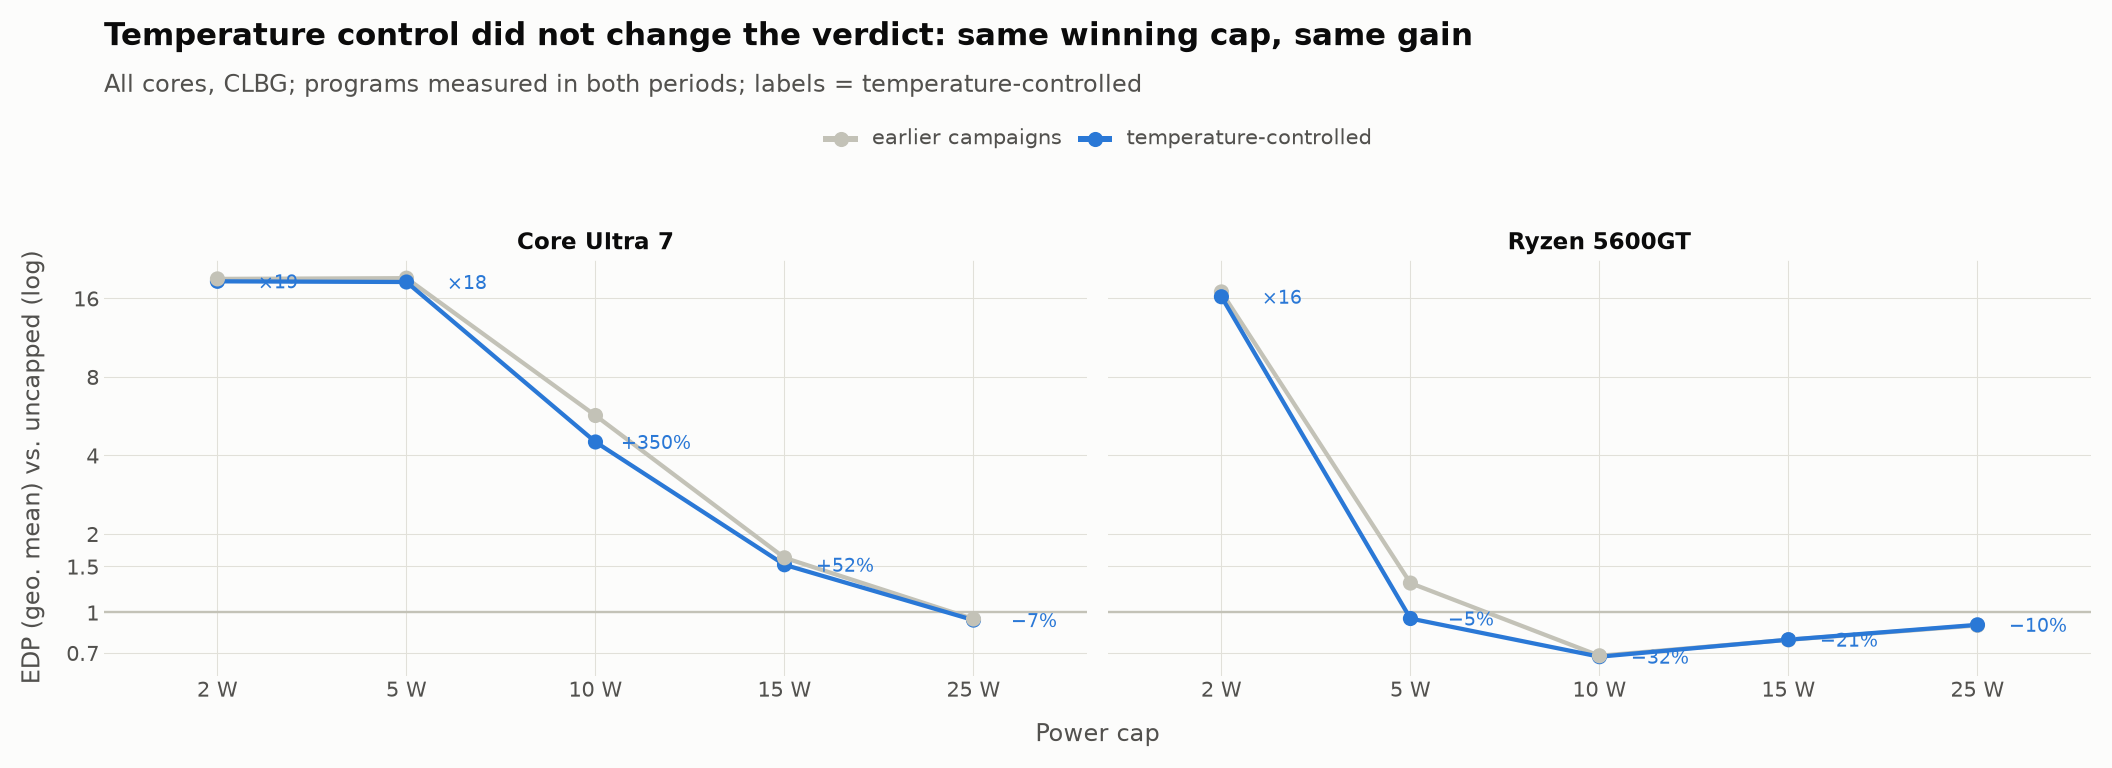

In [20]:
OLD_FILES = sorted(p for p in [*ROOT.glob('results/intel-CoreUltra7/*.csv'), *ROOT.glob('results/amd-ryzen5600gt/*.csv')]
                   if p not in FILES and not p.name.startswith('dacapo') and '06-11-2026-13:18:44' not in p.name)
old = (pl.concat([read_campaign(p).with_columns(**{k: pl.lit(v) for k, v in campaign_meta(p).items()}) for p in OLD_FILES],
                 how='diagonal_relaxed')
         .with_columns(pl.col('power_limit').cast(pl.Int32), cs.by_name(NUMERIC, require_all=False).cast(pl.Float64, strict=False))
         .drop_nulls(['pkg_j', 'time_ms'])
         .with_columns(E=pl.col('pkg_j'), T=pl.col('time_ms') / 1000, bench=pl.format('{} · {}', 'language', 'program'),
                       machine_label=pl.col('machine').replace_strict(MACHINE_LABEL, return_dtype=pl.String))
         .with_columns(EDP=pl.col('E') * pl.col('T')))
old_cell = old.group_by('machine_label', 'source', 'bench', 'power_limit').agg(pl.col('E', 'T', 'EDP').median())
old_ratio = (old_cell.filter(pl.col('power_limit') != -1)
                     .join(old_cell.filter(pl.col('power_limit') == -1).select('source', 'bench', EDP_base='EDP', E_base='E'),
                           on=['source', 'bench'])
                     .with_columns(EDP_ratio=pl.col('EDP') / pl.col('EDP_base'), E_ratio=pl.col('E') / pl.col('E_base')))
# per program: geometric mean over the campaigns of each period; only programs present in both periods
new_ratio = (ratio.filter(pl.col('cores') == 'multi', pl.col('group').cast(pl.String).str.ends_with('CLBG'))
                  .with_columns(machine_label=pl.col('machine').replace_strict(MACHINE_LABEL, return_dtype=pl.String),
                                bench=pl.col('bench').cast(pl.String)))
by_period = pl.concat([
    old_ratio.group_by('machine_label', 'bench', 'power_limit').agg(gmean('EDP_ratio'), gmean('E_ratio'))
             .with_columns(period=pl.lit('earlier campaigns')),
    new_ratio.group_by('machine_label', 'bench', 'power_limit').agg(gmean('EDP_ratio'), gmean('E_ratio'))
             .with_columns(period=pl.lit('temperature-controlled')),
])
common = by_period.group_by('machine_label', 'bench', 'power_limit').len().filter(pl.col('len') == 2)
by_period = by_period.join(common.drop('len'), on=['machine_label', 'bench', 'power_limit'])
then_now = (by_period.group_by('machine_label', 'period', 'power_limit').agg(programs=pl.len(), EDP=gmean('EDP_ratio'))
                     .with_columns(cap=pl.col('power_limit').map_elements(cap_label, return_dtype=pl.String)
                                         .cast(pl.Enum(CAP_ORDER))))
(ggplot(then_now, aes('cap', 'EDP', color='period', group='period'))
 + geom_hline(yintercept=1, color=AXIS)
 + geom_line(size=0.9)
 + geom_point(size=2.2)
 + geom_text(aes(label='label'), data=then_now.filter(pl.col('period') == 'temperature-controlled')
                                               .with_columns(label=pct_text('EDP')),
             nudge_x=0.32, size=7, show_legend=False)
 + scale_color_manual(values={'earlier campaigns': AXIS, 'temperature-controlled': SERIES}, name='')
 + scale_y_log10(breaks=[0.5, 0.7, 1, 1.5, 2, 4, 8, 16])
 + facet_wrap('machine_label', ncol=2)
 + labs(x='Power cap', y='EDP (geo. mean) vs. uncapped (log)',
        title='Temperature control did not change the verdict: same winning cap, same gain',
        subtitle='All cores, CLBG; programs measured in both periods; labels = temperature-controlled')
 + base_theme(11, 4) + theme(legend_position='top', legend_title=element_blank()))

In [21]:
# per program: does the verdict (gain > 2 %) agree between the two periods?
agreement = (by_period.sort('period').pivot(on='period', index=['machine_label', 'bench', 'power_limit'], values='EDP_ratio')
                      .with_columns(same_side=((pl.col('earlier campaigns') < 0.98) == (pl.col('temperature-controlled') < 0.98)))
                      .group_by('machine_label', 'power_limit')
                      .agg(programs=pl.len(), same_verdict=pl.col('same_side').mean(),
                           median_abs_diff=((pl.col('temperature-controlled') / pl.col('earlier campaigns')).log().abs().median().exp() - 1) * 100)
                      .sort('machine_label', 'power_limit'))
agreement.with_columns(cs.float().round(2))

machine_label,power_limit,programs,same_verdict,median_abs_diff
"""Core Ultra 7""",2,27,1.0,2.63
"""Core Ultra 7""",5,27,1.0,2.69
"""Core Ultra 7""",10,27,1.0,16.54
"""Core Ultra 7""",15,27,1.0,4.65
"""Core Ultra 7""",25,27,0.93,1.85
"""Ryzen 5600GT""",2,26,1.0,4.79
"""Ryzen 5600GT""",5,26,0.65,35.89
"""Ryzen 5600GT""",10,26,0.96,2.23
"""Ryzen 5600GT""",15,26,1.0,1.1
"""Ryzen 5600GT""",25,26,0.88,1.43


* Mesmo veredito em 88–100 % dos programas a 10–25 W.
* Só o 5600GT a 5 W mudou (+30 % → −5 %), um limite que já variava entre dias.

### 4.5 `intel-elite`: estimativa

Células com limite novas / execução sem limite das campanhas anteriores do `intel-elite`. Primeira tabela: deriva entre as
células com limite novas e as antigas.

In [22]:
DATA_OLD = {'multi': ['measurements-perf-0-14-10-2026-14:24:02.csv', 'measurements-perf-0-19-10-2026-10:21:22.csv',
                      'measurements-perf-1-04-11-2026-09:59:59.csv'],
            'single': ['measurements-perf-1-single-core-10-11-2026-17:47:04.csv']}
dold = (pl.concat([read_campaign(ROOT / 'data' / f).with_columns(cores=pl.lit(c), source=pl.lit(f))
                   for c, fs in DATA_OLD.items() for f in fs], how='diagonal_relaxed')
          .with_columns(pl.col('power_limit').cast(pl.Int32), cs.by_name(NUMERIC, require_all=False).cast(pl.Float64, strict=False))
          .drop_nulls(['pkg_j', 'time_ms'])
          .with_columns(pkg_j=pl.when(pl.col('pkg_j') < 0).then(pl.col('pkg_j') + WRAP_J).otherwise('pkg_j'))
          .with_columns(E=pl.col('pkg_j'), T=pl.col('time_ms') / 1000, bench=pl.format('{} · {}', 'language', 'program'))
          .with_columns(EDP=pl.col('E') * pl.col('T')))
dold_cell = (dold.group_by('cores', 'source', 'bench', 'power_limit').agg(pl.col('E', 'T', 'EDP').median())
                 .group_by('cores', 'bench', 'power_limit').agg(gmean('E'), gmean('T'), gmean('EDP')))
dnew = (cell.filter(pl.col('machine') == 'intel-elite').with_columns(bench=pl.col('bench').cast(pl.String))
            .select('cores', 'tool', 'bench', 'power_limit', 'cap', 'E', 'T', 'EDP'))
drift = (dnew.filter(pl.col('power_limit') != -1)
             .join(dold_cell, on=['cores', 'bench', 'power_limit'], suffix='_old')
             .group_by('cores', 'cap').agg(time_new_over_old=(pl.col('T') / pl.col('T_old')).log().mean().exp(),
                                           energy_new_over_old=(pl.col('E') / pl.col('E_old')).log().mean().exp())
             .sort('cores', 'cap'))
data_est = (dnew.filter(pl.col('power_limit') != -1)
                .join(dold_cell.filter(pl.col('power_limit') == -1).select('cores', 'bench', E_old='E', T_old='T', EDP_old='EDP'),
                      on=['cores', 'bench'])
                .group_by('cores', 'bench', 'cap').agg((pl.col('EDP') / pl.col('EDP_old')).log().mean().exp().alias('EDP_ratio'),
                                                       (pl.col('E') / pl.col('E_old')).log().mean().exp().alias('E_ratio'),
                                                       (pl.col('T') / pl.col('T_old')).log().mean().exp().alias('T_ratio'))
                .group_by('cores', 'cap').agg(programs=pl.len(), energy=gmean('E_ratio'), time=gmean('T_ratio'),
                                              EDP=gmean('EDP_ratio'), gain_over_2pct=(pl.col('EDP_ratio') < 0.98).sum())
                .sort('cores', 'cap'))
display(drift.with_columns(cs.float().round(3)))
data_est.select('cores', 'cap', 'programs', *as_pct('energy', 'time', 'EDP'), 'gain_over_2pct')

cores,cap,time_new_over_old,energy_new_over_old
"""multi""","""2 W""",1.038,1.092
"""multi""","""5 W""",1.044,1.044
"""multi""","""10 W""",1.018,1.023
"""multi""","""15 W""",1.014,1.021
"""multi""","""25 W""",1.015,1.015
"""single""","""2 W""",2.608,2.647
"""single""","""5 W""",1.081,1.081
"""single""","""10 W""",1.043,1.047
"""single""","""15 W""",1.032,1.06
"""single""","""25 W""",1.032,1.059


cores,cap,programs,energy %,time %,EDP %,gain_over_2pct
"""multi""","""2 W""",27,-40.1,329.9,157.1,0
"""multi""","""5 W""",27,-43.5,139.7,35.4,2
"""multi""","""10 W""",27,-33.1,42.4,-4.8,16
"""multi""","""15 W""",27,-22.5,19.0,-7.8,19
"""multi""","""25 W""",27,-4.7,5.9,0.9,6
"""single""","""2 W""",27,57.9,799.3,1320.2,0
"""single""","""5 W""",27,-30.2,59.7,11.5,0
"""single""","""10 W""",27,-2.4,11.6,8.9,2
"""single""","""15 W""",27,6.9,3.4,10.5,2
"""single""","""25 W""",27,7.6,3.3,11.2,1


* Todos os núcleos: 15 W (−8 %) e 10 W (−5 %) vencem.
* 1 núcleo: nenhum limite vence; 10–25 W ficam 9–11 % piores, o tamanho da deriva.
* É estimativa: rodar de novo o bloco `-1` resolve.

## 5 · 1 núcleo vs. todos os núcleos

Razão = 1 núcleo / todos os núcleos (> 1 = 1 núcleo é pior). 8500G fora (sem campanha de 1 núcleo).

### 5.1 Speedup

Programas com speedup < 1.35× são chamados de **seriais**.

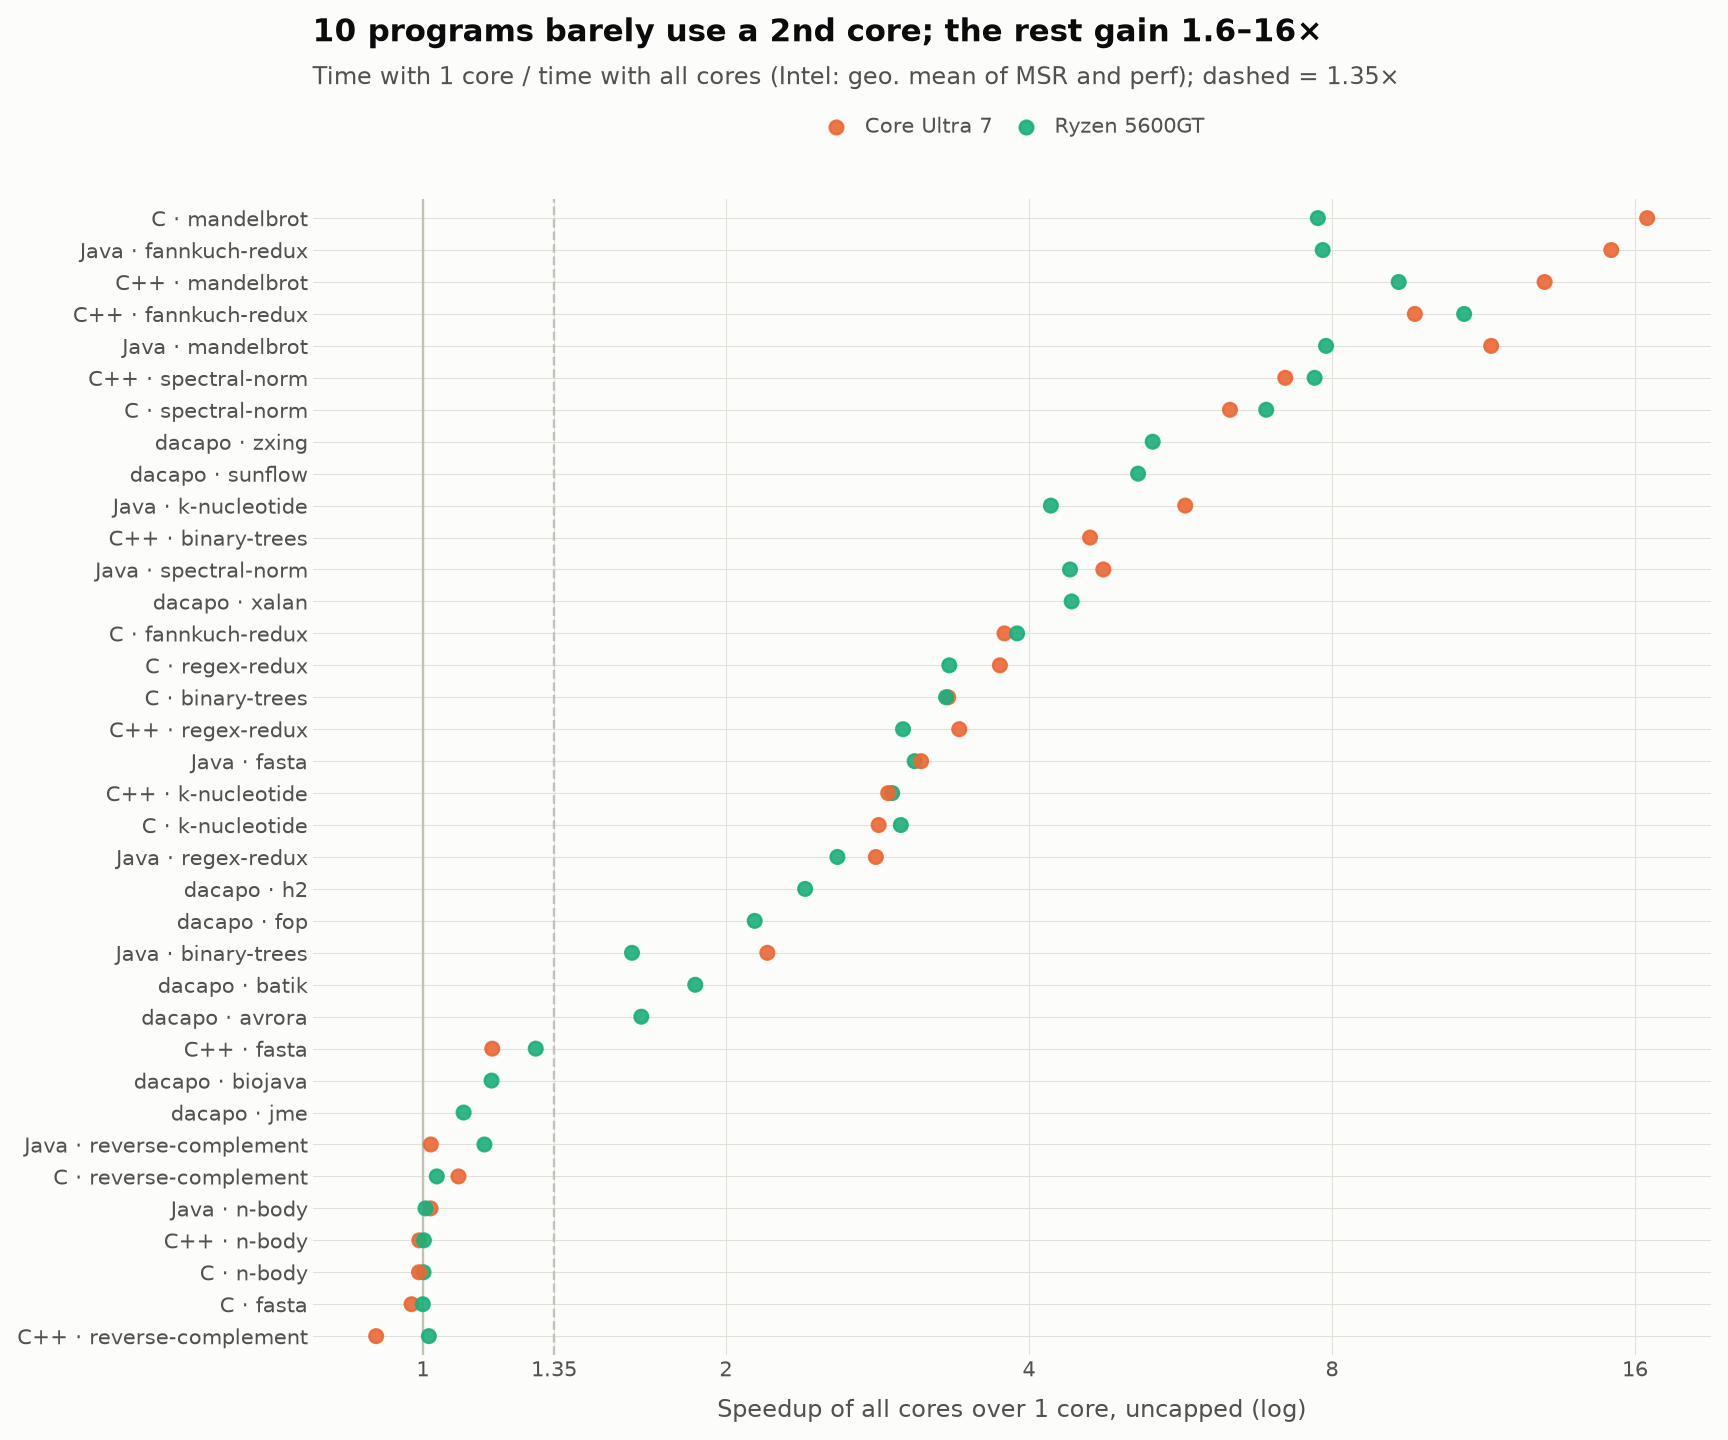

In [23]:
pair_keys = ['machine', 'group', 'tool', 'bench', 'power_limit', 'cap']
one = cell.filter(pl.col('cores') == 'single').select(*pair_keys, 'baseline_ok', 'E', 'T', 'P', 'EDP')
allc = cell.filter(pl.col('cores') == 'multi').select(*pair_keys, 'baseline_ok', 'E', 'T', 'P', 'EDP')
sm = (one.join(allc, on=pair_keys, suffix='_all')
         .filter((pl.col('power_limit') != -1) | (pl.col('baseline_ok') & pl.col('baseline_ok_all')))
         .with_columns(T_ratio=pl.col('T') / pl.col('T_all'), E_ratio=pl.col('E') / pl.col('E_all'),
                       P_ratio=pl.col('P') / pl.col('P_all'), EDP_ratio=pl.col('EDP') / pl.col('EDP_all'),
                       machine_label=pl.col('machine').replace_strict(MACHINE_LABEL, return_dtype=pl.String)))
speedup = (sm.filter(pl.col('power_limit') == -1)
             .group_by('machine_label', 'group', 'bench').agg(speedup=gmean('T_ratio')))
SERIAL_MAX = 1.35
kind = (speedup.group_by('bench').agg(speedup_median=pl.col('speedup').median())
               .with_columns(kind=pl.when(pl.col('speedup_median') < SERIAL_MAX).then(pl.lit('serial'))
                                    .otherwise(pl.lit('parallel'))))
sm = sm.join(kind.select('bench', 'kind'), on='bench')
spd_order = kind.sort('speedup_median')['bench'].cast(pl.String).to_list()
(ggplot(speedup.with_columns(bench=pl.col('bench').cast(pl.String)), aes('speedup', 'bench', color='machine_label'))
 + geom_vline(xintercept=1, color=AXIS)
 + geom_vline(xintercept=SERIAL_MAX, color=AXIS, linetype='dashed')
 + geom_point(size=2.4, alpha=0.9)
 + scale_color_manual(values=MACHINE_COLOR, name='')
 + scale_x_log10(breaks=[1, 1.35, 2, 4, 8, 16])
 + scale_y_discrete(limits=spd_order)
 + labs(x='Speedup of all cores over 1 core, uncapped (log)', y='',
        title='10 programs barely use a 2nd core; the rest gain 1.6–16×',
        subtitle='Time with 1 core / time with all cores (Intel: geo. mean of MSR and perf); dashed = 1.35×')
 + base_theme(9, 7.5) + theme(legend_position='top', legend_title=element_blank()))

* Seriais (10): n-body, C/C++ fasta, reverse-complement e os DaCapo `biojava` e `jme`.
* Paralelos: até 16× no Core Ultra 7 e ~11× no 5600GT.

### 5.2 Uso dos núcleos

**CPUs ocupadas** = (user + system) / tempo real, só nas campanhas `perf`. **Eficiência** = speedup / CPUs ocupadas.
Todos os núcleos, sem limite.

1-core runs: busy CPUs median 1.000, max of per-cell medians 1.04, user/system times that are multiples of 10 ms: 100%


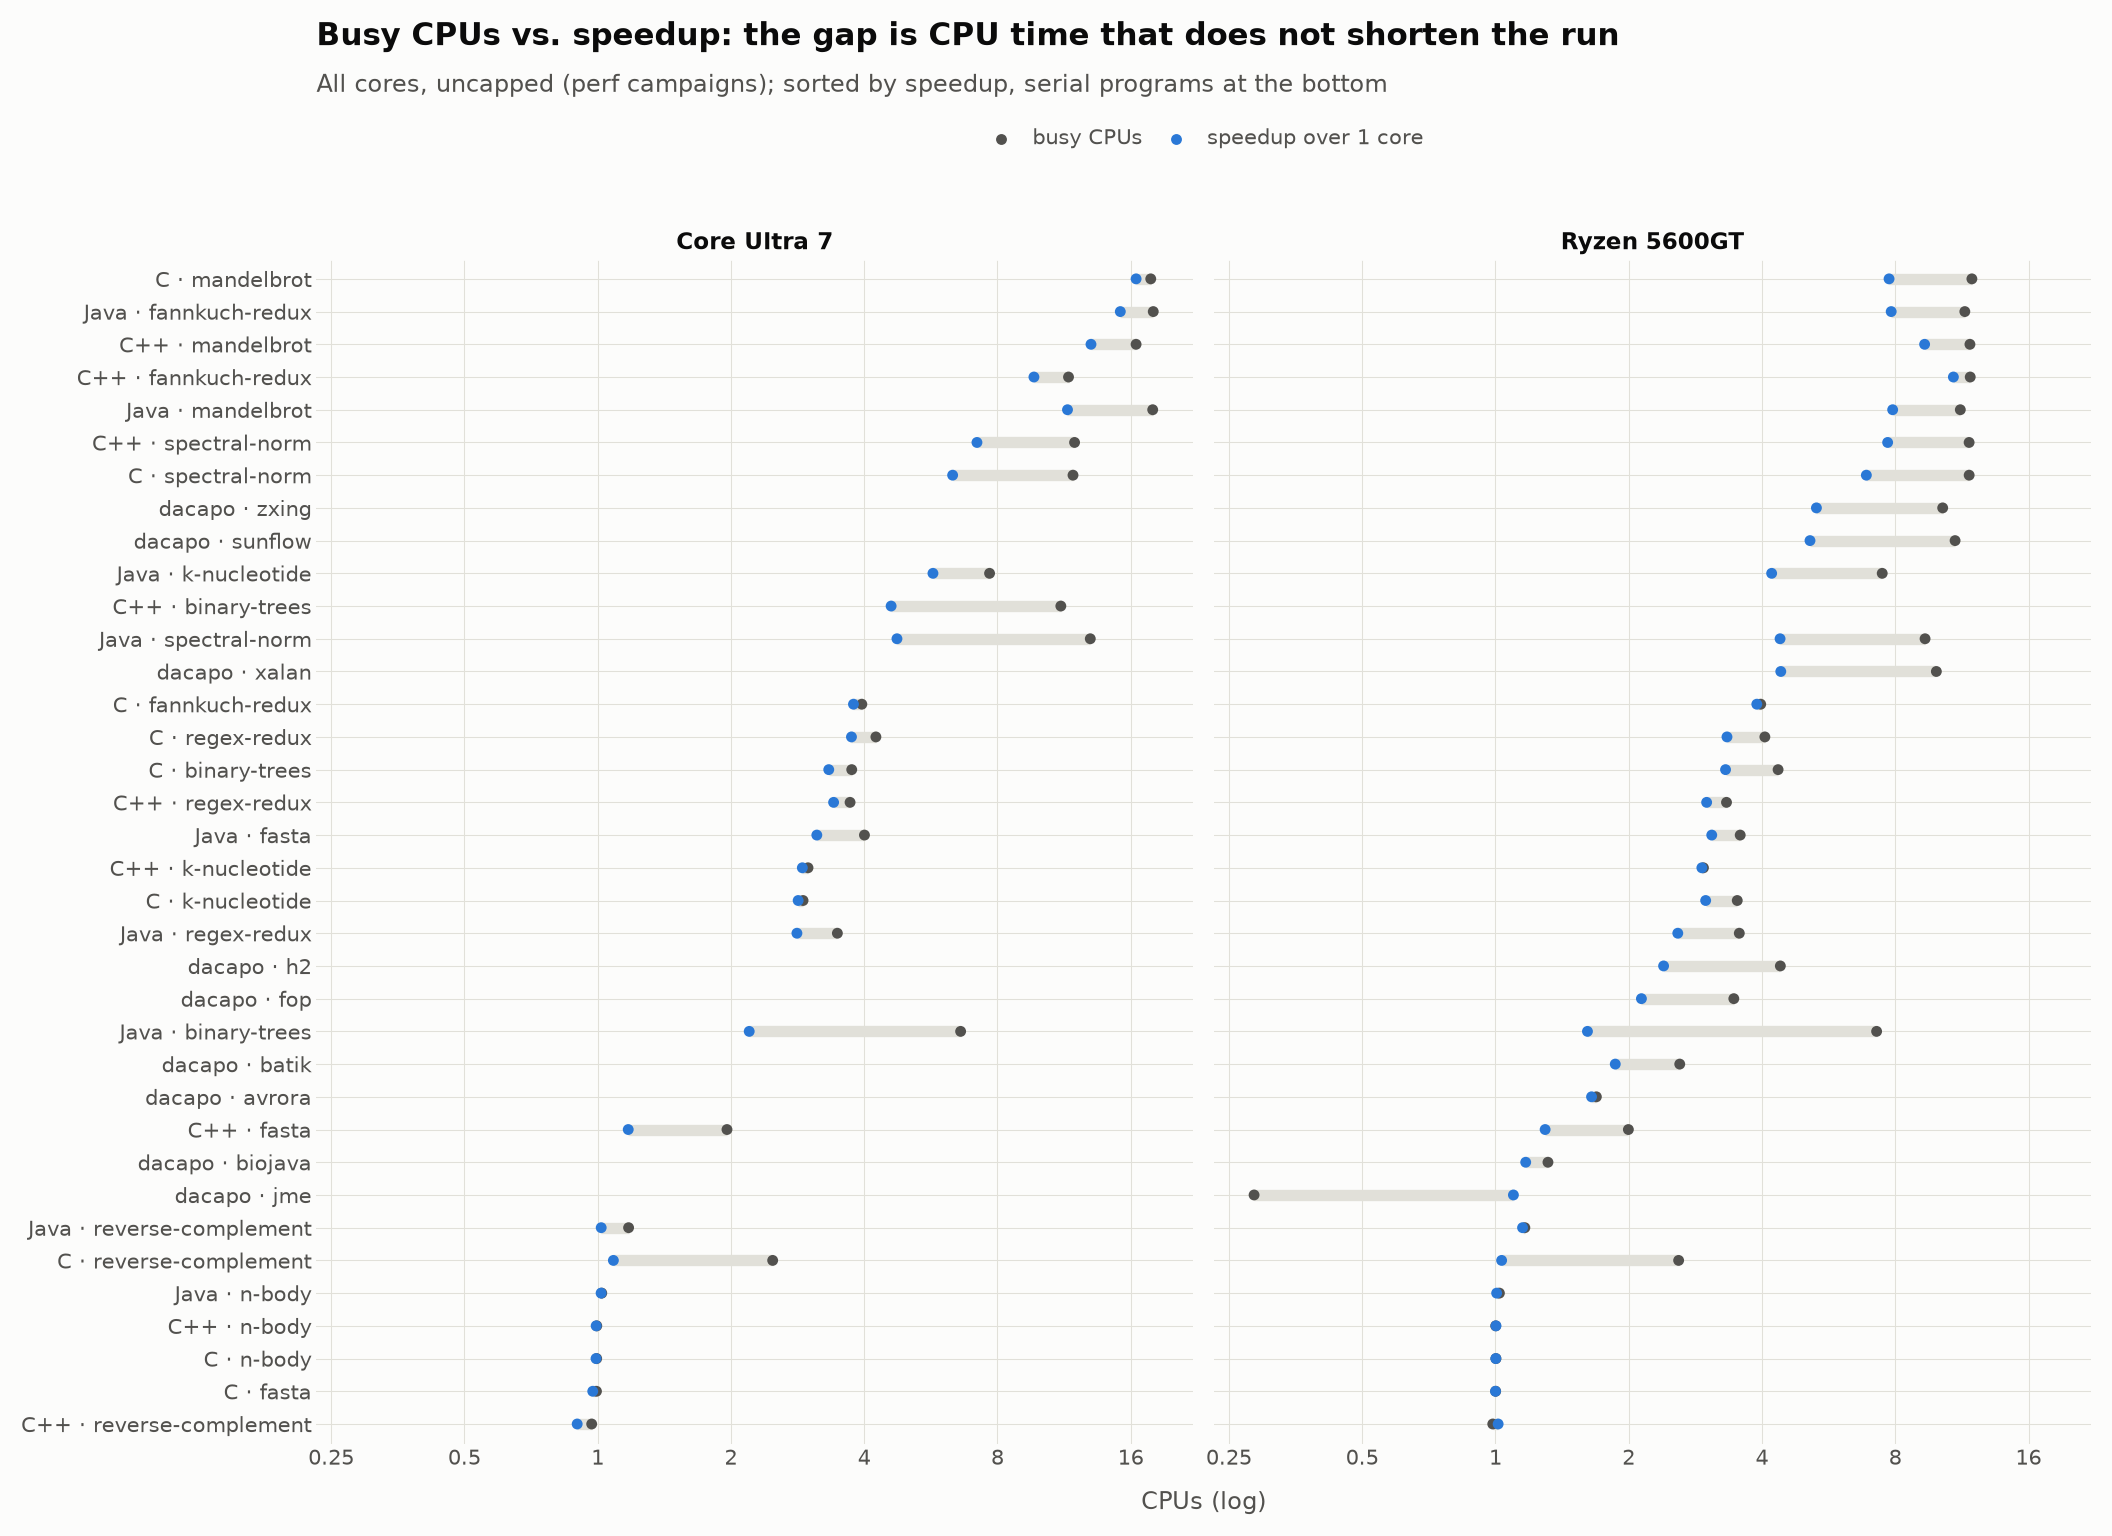

In [24]:
busy_runs = (clean.filter(pl.col('tool') == 'perf', pl.col('user_ms').is_not_null())
                  .with_columns(busy=(pl.col('user_ms') + pl.col('sys_ms').fill_null(0)) / pl.col('time_ms')))
# sanity check: with 1 CPU online this should be ~1. user/system time comes in 10 ms ticks (time_ms is exact),
# so runs of ~0.1 s can land a few % above 1
one_busy = busy_runs.filter(pl.col('cores') == 'single')
print(f"1-core runs: busy CPUs median {one_busy['busy'].median():.3f}, max of per-cell medians "
      f"{one_busy.group_by('campaign', 'bench', 'cap').agg(pl.col('busy').median())['busy'].max():.2f}, "
      f"user/system times that are multiples of 10 ms: {(one_busy['user_ms'] % 10 == 0).mean():.0%}")
busy = (busy_runs.filter(pl.col('cores') == 'multi',
                         pl.when('baseline_ok').then(pl.col('power_limit') == -1).otherwise(pl.col('power_limit') == 25))
                 .group_by('machine_label', 'bench').agg(busy=pl.col('busy').median()))
par = (busy.join(speedup.select('machine_label', 'bench', 'speedup'), on=['machine_label', 'bench'], how='left')
           .with_columns(efficiency=pl.col('speedup') / pl.col('busy')))

# per program: busy CPUs vs. speedup (machines with a valid uncapped run)
db = par.filter(pl.col('speedup').is_not_null()).with_columns(bench=pl.col('bench').cast(pl.String))
db_long = db.unpivot(index=['machine_label', 'bench'], on=['busy', 'speedup'], variable_name='measure', value_name='cpus')
(ggplot(db, aes(y='bench'))
 + geom_segment(aes(x='speedup', xend='busy', yend='bench'), color=GRID, size=2.4)
 + geom_point(aes(x='cpus', color='measure'), data=db_long, size=2.3, stroke=0)
 + scale_color_manual(values={'busy': INK2, 'speedup': SERIES},
                      labels={'busy': 'busy CPUs', 'speedup': 'speedup over 1 core'})
 + scale_x_log10(breaks=[0.25, 0.5, 1, 2, 4, 8, 16])
 + scale_y_discrete(limits=[b for b in spd_order if b in set(db['bench'])])
 + facet_wrap('machine_label', ncol=2)
 + labs(x='CPUs (log)', y='', title='Busy CPUs vs. speedup: the gap is CPU time that does not shorten the run',
        subtitle='All cores, uncapped (perf campaigns); sorted by speedup, serial programs at the bottom')
 + base_theme(11, 8) + theme(legend_position='top', legend_title=element_blank()))

* Barra cinza = CPUs ocupadas que não viram speedup.
* Java binary-trees ocupa ~7 CPUs para speedup de ~2× (coletor de lixo); C reverse-complement ocupa 2.5 CPUs sem
  ganhar nada; DaCapo `jme` ocupa só 0.3 CPU.
* Com 1 núcleo, a mediana é 1.00 CPU: o `cores_on_off.sh` funcionou. O máximo de 1.04 é arredondamento: user e
  system vêm em passos de 10 ms e o tempo real em ms, então execuções de ~0.1 s passam de 1 por alguns %.

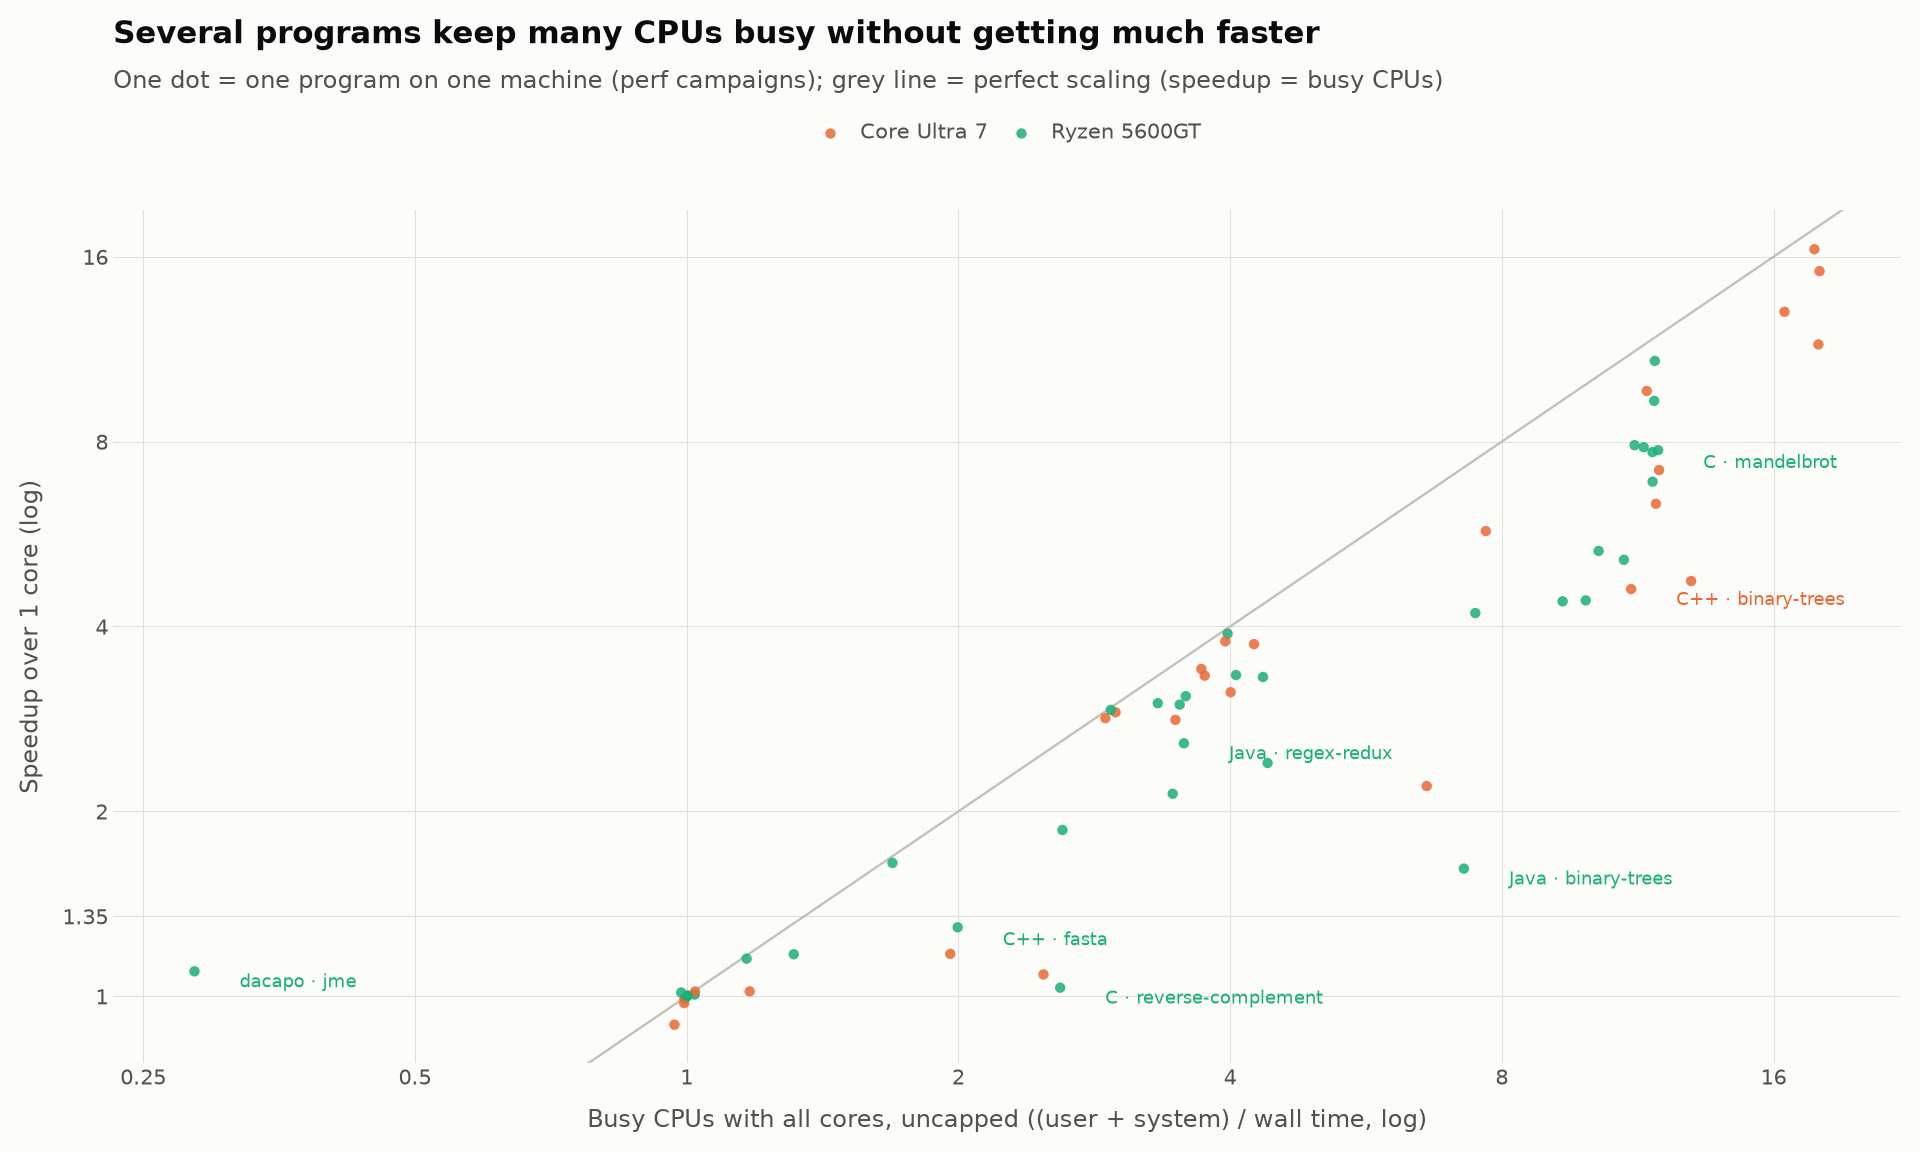

In [25]:
PAR_LABELS = ['Java · binary-trees', 'C · reverse-complement', 'C++ · fasta', 'C++ · binary-trees', 'dacapo · jme',
              'C · mandelbrot', 'Java · regex-redux']
pts_par = par.filter(pl.col('speedup').is_not_null()).with_columns(bench=pl.col('bench').cast(pl.String))
labels_par = pts_par.filter(pl.col('bench').is_in(PAR_LABELS),
                            (pl.col('machine_label') == 'Ryzen 5600GT') | (pl.col('bench') == 'C++ · binary-trees'))
(ggplot(pts_par, aes('busy', 'speedup', color='machine_label'))
 + geom_abline(intercept=0, slope=1, color=AXIS)
 + geom_point(size=2.2, alpha=0.85, stroke=0)
 + geom_text(aes(label='bench'), data=labels_par, size=6.8, nudge_x=0.05, ha='left', va='top', show_legend=False)
 + scale_color_manual(values=MACHINE_COLOR)
 + scale_x_log10(breaks=[0.25, 0.5, 1, 2, 4, 8, 16])
 + scale_y_log10(breaks=[1, 1.35, 2, 4, 8, 16])
 + labs(x='Busy CPUs with all cores, uncapped ((user + system) / wall time, log)',
        y='Speedup over 1 core (log)',
        title='Several programs keep many CPUs busy without getting much faster',
        subtitle='One dot = one program on one machine (perf campaigns); grey line = perfect scaling (speedup = busy CPUs)')
 + base_theme(10, 6) + theme(legend_position='top', legend_title=element_blank()))

* Perto da diagonal: k-nucleotide, regex-redux, fannkuch-redux, mandelbrot (Core Ultra 7).
* No 5600GT, quem ocupa as 12 CPUs fica abaixo dela: duas threads SMT dividem um núcleo.

**Programas pouco eficientes ganham mais com o limite?** (só paralelos, nos limites que vencem)

In [26]:
eff_gain = []
for setup, w in [('Core Ultra 7 · CLBG · all cores', 25), ('Ryzen 5600GT · CLBG · all cores', 10),
                 ('Ryzen 5600GT · CLBG · all cores', 15), ('Ryzen 5600GT · DaCapo · all cores', 10)]:
    j = (setup_ratio.filter(pl.col('setup').cast(pl.String) == setup, pl.col('power_limit') == w)
                    .join(par.filter(pl.col('machine_label') == setup.split(' · ')[0]), on='bench')
                    .join(kind.filter(pl.col('kind') == 'parallel').select('bench'), on='bench')
                    .drop_nulls('efficiency'))
    low, high = pl.col('efficiency') < 0.6, pl.col('efficiency') >= 0.85
    eff_gain.append(j.select(setup=pl.lit(setup), cap=pl.lit(f'{w} W'), programs=pl.len(),
                             spearman_rho=pl.corr('efficiency', 'EDP_ratio', method='spearman'),
                             n_low=low.sum(), EDP_low=pl.col('EDP_ratio').filter(low).log().mean().exp(),
                             n_high=high.sum(), EDP_high=pl.col('EDP_ratio').filter(high).log().mean().exp()))
(pl.concat(eff_gain).with_columns(pl.col('spearman_rho').round(2), *as_pct('EDP_low', 'EDP_high'))
   .drop('EDP_low', 'EDP_high')
   .rename({'n_low': 'programs eff<0.6', 'n_high': 'programs eff≥0.85', 'EDP_low %': 'EDP eff<0.6 %',
            'EDP_high %': 'EDP eff≥0.85 %'}))

setup,cap,programs,spearman_rho,programs eff<0.6,programs eff≥0.85,EDP eff<0.6 %,EDP eff≥0.85 %
"""Core Ultra 7 · CLBG · all cores""","""25 W""",19,0.42,4,7,-36.6,-7.6
"""Ryzen 5600GT · CLBG · all cores""","""10 W""",18,0.59,4,5,-42.7,-33.9
"""Ryzen 5600GT · CLBG · all cores""","""15 W""",18,0.48,4,5,-31.1,-24.6
"""Ryzen 5600GT · DaCapo · all cores""","""10 W""",7,0.07,4,1,-32.7,-18.3


Tendência fraca (ρ 0.4–0.6 no CLBG): no 5600GT a 10 W, os pouco eficientes ganham 43 % e os eficientes, 34 %. Com 4–7 programas por grupo, é hipótese.

### 5.3 Custo de 1 núcleo, sem limite

$EDP_\text{1 núcleo}/EDP_\text{todos} = P_\text{razão}\cdot T_\text{razão}^2$

group,kind,programs,time %,power %,energy %,EDP %,one_core_better_EDP,one_core_better_energy
"""Core Ultra 7 · CLBG""","""parallel""",19,427.4,-67.5,71.3,803.2,0,1
"""Core Ultra 7 · CLBG""","""serial""",8,1.6,-5.7,-4.0,-2.3,5,5
"""Ryzen 5600GT · CLBG""","""parallel""",18,354.4,-54.7,105.6,833.6,0,0
"""Ryzen 5600GT · CLBG""","""serial""",8,5.9,-4.8,0.8,6.8,1,1
"""Ryzen 5600GT · DaCapo""","""parallel""",7,193.9,-46.8,56.0,358.1,0,0
"""Ryzen 5600GT · DaCapo""","""serial""",2,13.3,2.2,16.0,31.5,0,0


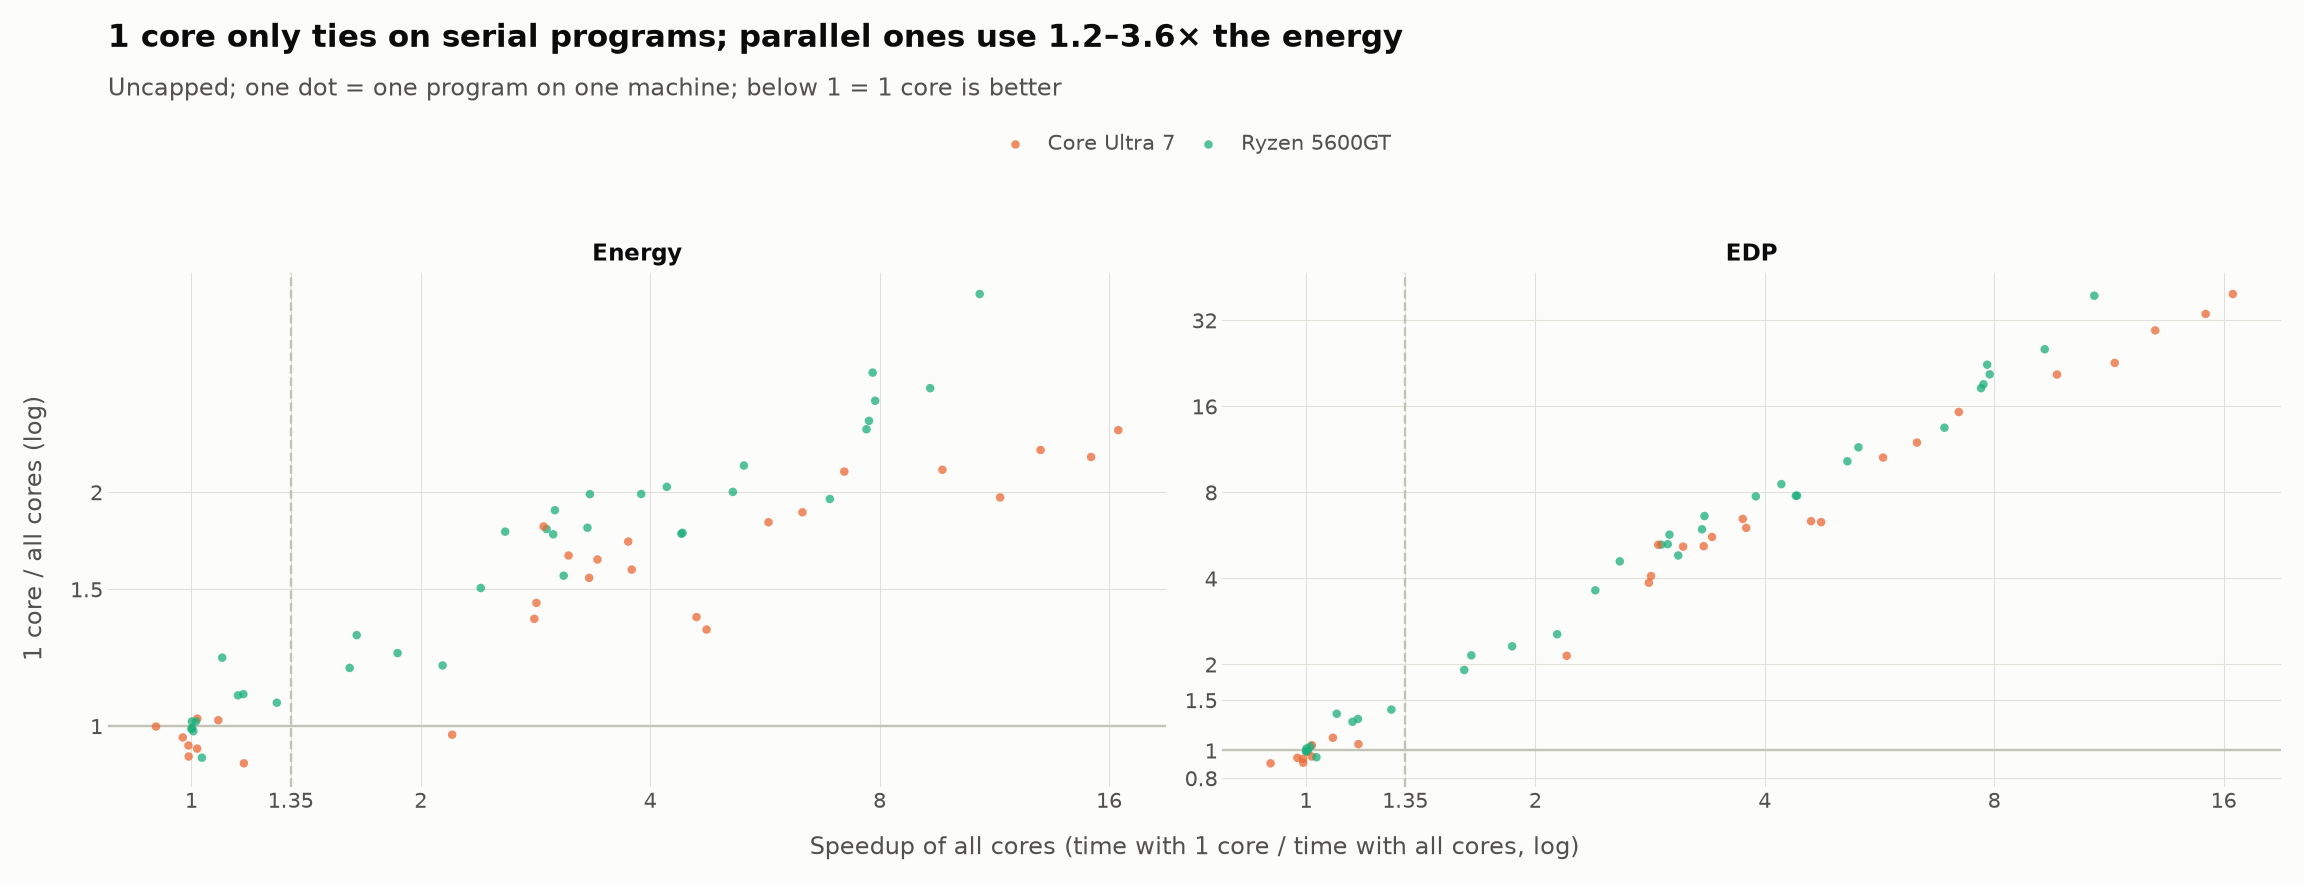

In [27]:
# one value per program and machine (Intel: geometric mean of the MSR and perf campaigns)
uncapped_sm = (sm.filter(pl.col('power_limit') == -1)
                 .group_by('machine_label', 'group', 'bench', 'kind')
                 .agg(gmean('T_ratio'), gmean('P_ratio'), gmean('E_ratio'), gmean('EDP_ratio')))
cost = (uncapped_sm.group_by('machine_label', 'group', 'kind')
                   .agg(programs=pl.len(), time=gmean('T_ratio'), power=gmean('P_ratio'),
                        energy=gmean('E_ratio'), EDP=gmean('EDP_ratio'),
                        one_core_better_EDP=(pl.col('EDP_ratio') < 0.98).sum(),
                        one_core_better_energy=(pl.col('E_ratio') < 0.98).sum())
                   .sort('group', 'kind'))
display(cost.select('group', 'kind', 'programs', *as_pct('time', 'power', 'energy', 'EDP'),
                    'one_core_better_EDP', 'one_core_better_energy'))

pts = (uncapped_sm.unpivot(index=['machine_label', 'group', 'bench', 'kind', 'T_ratio'],
                           on=['E_ratio', 'EDP_ratio'], variable_name='metric', value_name='ratio')
                  .with_columns(metric=pl.col('metric').replace_strict({'E_ratio': 'Energy', 'EDP_ratio': 'EDP'})
                                          .cast(pl.Enum(['Energy', 'EDP']))))
(ggplot(pts, aes('T_ratio', 'ratio', color='machine_label'))
 + geom_hline(yintercept=1, color=AXIS)
 + geom_vline(xintercept=SERIAL_MAX, color=AXIS, linetype='dashed')
 + geom_point(size=1.8, alpha=0.75, stroke=0)
 + scale_color_manual(values=MACHINE_COLOR, name='')
 + scale_x_log10(breaks=[1, 1.35, 2, 4, 8, 16])
 + scale_y_log10(breaks=[0.8, 1, 1.5, 2, 4, 8, 16, 32])
 + facet_wrap('metric', ncol=2, scales='free_y')
 + labs(x='Speedup of all cores (time with 1 core / time with all cores, log)', y='1 core / all cores (log)',
        title='1 core only ties on serial programs; parallel ones use 1.2–3.6× the energy',
        subtitle='Uncapped; one dot = one program on one machine; below 1 = 1 core is better')
 + base_theme(12, 4.6) + theme(legend_position='top', legend_title=element_blank()))

* Paralelos: 3–5× mais lentos, +56–106 % de energia, EDP ×4.6–9.3. Nenhum melhora com 1 núcleo.
* Seriais: empate (±5 %).

### 5.4 Mesmo limite nos dois modos

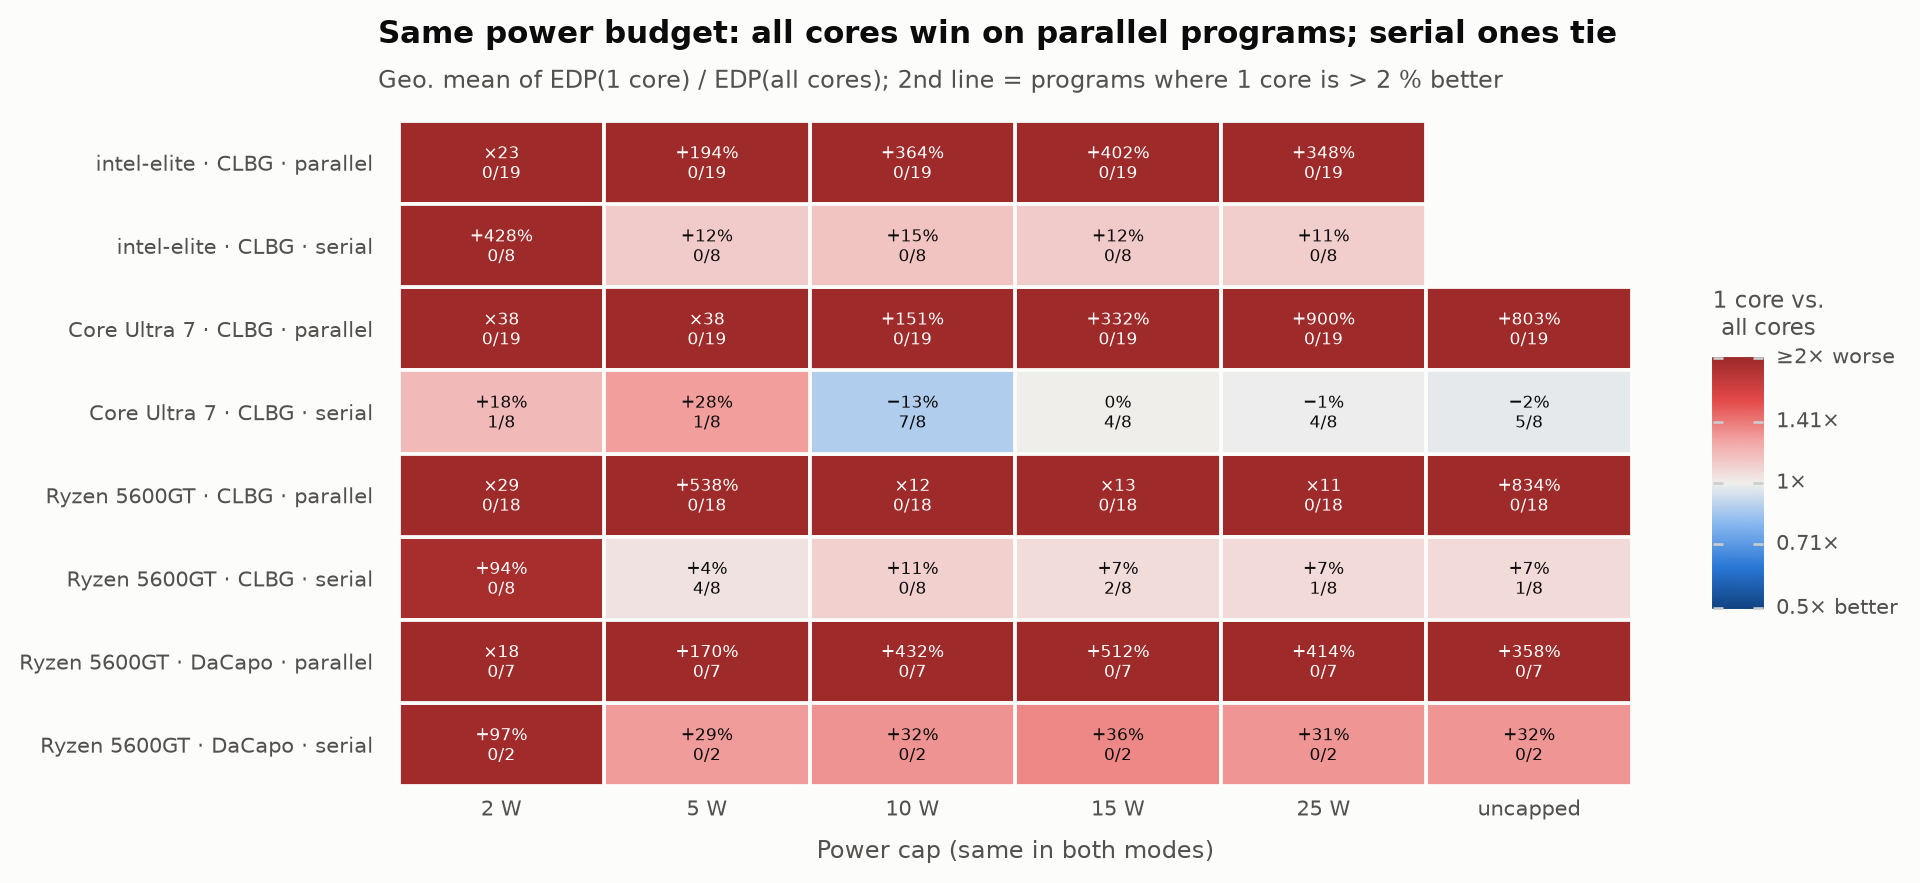

In [28]:
budget = (sm.group_by('group', 'kind', 'bench', 'cap').agg(gmean('EDP_ratio'), gmean('E_ratio'))  # combine MSR and perf
            .group_by('group', 'kind', 'cap')
            .agg(EDP=gmean('EDP_ratio'), energy=gmean('E_ratio'), n=pl.len(),
                 one_core_wins=(pl.col('EDP_ratio') < 0.98).sum())
            .with_columns(row=pl.format('{} · {}', 'group', 'kind'), l2=pl.col('EDP').log(2).clip(-1, 1),
                          label=pl.format('{}\n{}/{}', pct_text('EDP'), 'one_core_wins', 'n'))
            .with_columns(txt=tile_text_color()))
ROWS = [f'{g} · {k}' for g in GROUPS for k in ['parallel', 'serial'] if f'{g} · {k}' in set(budget['row'])]
(ggplot(budget, aes('cap', 'row'))
 + geom_tile(aes(fill='l2'), color=SURFACE, size=0.8)
 + geom_text(aes(label='label', color='txt'), size=6.5)
 + scale_color_identity()
 + ratio_fill('1 core vs.\nall cores')
 + scale_y_discrete(limits=ROWS[::-1])
 + labs(x='Power cap (same in both modes)', y='',
        title='Same power budget: all cores win on parallel programs; serial ones tie',
        subtitle='Geo. mean of EDP(1 core) / EDP(all cores); 2nd line = programs where 1 core is > 2 % better')
 + base_theme(10, 4.6) + HEAT)

* Paralelos: todos os núcleos têm EDP 2.5–38× menor em todo limite.
* Seriais: empate no Core Ultra 7; no 5600GT e no `intel-elite`, todos os núcleos ganham 4–15 %.

### 5.5 Melhor configuração por programa

Menor EDP e menor energia entre as 12 configurações (núcleos × limite).

In [29]:
cand = cell.filter((pl.col('power_limit') != -1) | pl.col('baseline_ok'))
best_cfg = (cand.group_by('machine', 'group', 'cores', 'bench', 'power_limit', 'cap')
                .agg(gmean('EDP'), gmean('E'), gmean('T'))                 # Intel: combine MSR and perf
                .with_columns(config=pl.format('{} · {}', pl.col('cores').replace_strict(CORES, return_dtype=pl.String),
                                               pl.col('cap').cast(pl.String))))


def best_by(metric):
    b = best_cfg.sort(metric).group_by('group', 'bench', 'cores', maintain_order=True).first()
    w = b.pivot(on='cores', index=['group', 'bench'], values=[metric, 'config'])
    return w.with_columns(one_core_vs_best_all=pl.col(f'{metric}_single') / pl.col(f'{metric}_multi'))


best_EDP, best_E = best_by('EDP'), best_by('E')
summary_cfg = pl.concat([
    b.drop_nulls('one_core_vs_best_all').group_by('group').agg(programs=pl.len(), one_core_better=(pl.col('one_core_vs_best_all') < 0.98).sum(),
                            tie=(pl.col('one_core_vs_best_all').is_between(0.98, 1.02)).sum(),
                            median_one_core_vs_best_all=((pl.col('one_core_vs_best_all').median() - 1) * 100).round(1))
     .with_columns(metric=pl.lit(m))
    for m, b in [('EDP', best_EDP), ('energy', best_E)]]).sort('metric', 'group')
display(summary_cfg)
print('Programs whose best 1-core configuration beats the best all-core one by > 2 %:')
pl.concat([b.filter(pl.col('one_core_vs_best_all') < 0.98)
            .select('group', 'bench', pl.lit(m).alias('metric'), best_all=f'config_multi', best_one=f'config_single',
                    gain_pct=((pl.col('one_core_vs_best_all') - 1) * 100).round(1))
           for m, b in [('EDP', best_EDP), ('energy', best_E)]]).sort('metric', 'group', 'gain_pct')

group,programs,one_core_better,tie,median_one_core_vs_best_all,metric
"""intel-elite · CLBG""",27,0,1,305.4,"""EDP"""
"""Core Ultra 7 · CLBG""",27,4,1,464.9,"""EDP"""
"""Ryzen 5600GT · CLBG""",26,3,2,526.5,"""EDP"""
"""Ryzen 5600GT · DaCapo""",10,0,0,246.3,"""EDP"""
"""intel-elite · CLBG""",27,0,0,58.4,"""energy"""
"""Core Ultra 7 · CLBG""",27,3,5,99.7,"""energy"""
"""Ryzen 5600GT · CLBG""",26,4,2,116.9,"""energy"""
"""Ryzen 5600GT · DaCapo""",10,0,0,54.5,"""energy"""


Programs whose best 1-core configuration beats the best all-core one by > 2 %:


group,bench,metric,best_all,best_one,gain_pct
"""Core Ultra 7 · CLBG""","""C++ · reverse-complement""","""EDP""","""all cores · 15 W""","""1 core · 15 W""",-13.9
"""Core Ultra 7 · CLBG""","""C · n-body""","""EDP""","""all cores · 15 W""","""1 core · 15 W""",-7.0
"""Core Ultra 7 · CLBG""","""C · fasta""","""EDP""","""all cores · 15 W""","""1 core · 15 W""",-6.6
"""Core Ultra 7 · CLBG""","""C++ · n-body""","""EDP""","""all cores · 15 W""","""1 core · 15 W""",-4.2
"""Ryzen 5600GT · CLBG""","""C · fasta""","""EDP""","""all cores · 5 W""","""1 core · 5 W""",-7.4
"""Ryzen 5600GT · CLBG""","""Java · n-body""","""EDP""","""all cores · 5 W""","""1 core · 5 W""",-4.5
"""Ryzen 5600GT · CLBG""","""C · n-body""","""EDP""","""all cores · 5 W""","""1 core · 5 W""",-4.3
"""Core Ultra 7 · CLBG""","""C++ · reverse-complement""","""energy""","""all cores · 10 W""","""1 core · 15 W""",-7.3
"""Core Ultra 7 · CLBG""","""C · n-body""","""energy""","""all cores · 15 W""","""1 core · 15 W""",-3.5
"""Core Ultra 7 · CLBG""","""C · fasta""","""energy""","""all cores · 10 W""","""1 core · 10 W""",-3.2


In [30]:
# which all-core and one-core configurations are best, per machine (counts of programs)
(best_cfg.sort('EDP').group_by('group', 'bench', 'cores', maintain_order=True).first()
         .group_by('group', 'cores', 'cap').len()
         .pivot(on='cap', index=['group', 'cores'], values='len', sort_columns=True).fill_null(0).sort('group', 'cores'))

group,cores,5 W,10 W,15 W,25 W,uncapped
"""intel-elite · CLBG""","""multi""",2,9,16,0,0
"""intel-elite · CLBG""","""single""",7,15,5,0,0
"""Core Ultra 7 · CLBG""","""multi""",0,0,8,13,6
"""Core Ultra 7 · CLBG""","""single""",0,0,26,0,1
"""Ryzen 5600GT · CLBG""","""multi""",7,19,0,0,0
"""Ryzen 5600GT · CLBG""","""single""",24,2,0,0,0
"""Ryzen 5600GT · DaCapo""","""multi""",3,6,1,0,0
"""Ryzen 5600GT · DaCapo""","""single""",10,0,0,0,0
"""Ryzen 8500G · CLBG""","""multi""",0,7,5,15,0
"""Ryzen 8500G · DaCapo""","""multi""",0,10,9,0,1


* 1 núcleo vence em 7 de 90 pares (programa, máquina), todos seriais, por 4–14 % de EDP.
* Melhor limite com todos os núcleos: 25 W no Core Ultra 7, 10 W no 5600GT, 15 W no `intel-elite`, 25 W no 8500G
  (CLBG; no DaCapo, 10–15 W). Com 1 núcleo: 15 W,
  5 W e 10 W.

## 6 · Conclusões

| Cenário | Melhor limite | EDP | IC 95 % | Melhor / empate / pior |
|---|---|---|---|---|
| Core Ultra 7 · todos os núcleos | 25 W | −6.6 % | −14.8 … +2.6 % | 14 / 7 / 6 |
| Core Ultra 7 · 1 núcleo | 15 W | **−8.7 %** | −10.2 … −7.2 % | 24 / 3 / 0 |
| 5600GT · CLBG · todos os núcleos | 10 W | **−32.4 %** | −36.4 … −27.9 % | 26 / 0 / 0 |
| 5600GT · CLBG · 1 núcleo | 5 W | **−27.8 %** | −29.2 … −26.6 % | 26 / 0 / 0 |
| 5600GT · DaCapo · todos os núcleos | 10 W | **−28.5 %** | −34.5 … −21.7 % | 8 / 1 / 0 |
| 5600GT · DaCapo · 1 núcleo | 5 W | **−24.4 %** | −27.2 … −21.3 % | 10 / 0 / 0 |
| 8500G · CLBG · todos os núcleos (*sem controle*) | 25 W | **−11.3 %** | −14.3 … −8.3 % | 20 / 7 / 0 |
| 8500G · DaCapo · todos os núcleos (*sem controle*) | 15 W | **−10.8 %** | −16.0 … −6.0 % | 14 / 3 / 3 |
| `intel-elite` · todos os núcleos (*estimativa*) | 15 W | ≈ −8 % | — | — |

* **Precisão:** melhorou (limites sem efeito movem ~0 %; antes, ±2 %). Os vereditos são os mesmos de antes em 88–100 %
  dos programas a 2, 10, 15 e 25 W (CLBG com todos os núcleos, Core Ultra 7 e 5600GT); a 5 W, o 5600GT mudou em 9 de
  26 programas, de piora para ganho.
* **Limite:** o 5600GT ganha 24–32 % de EDP e nenhum programa piora (um empate, no DaCapo com todos os núcleos); o Core Ultra 7 quase não ganha com todos os núcleos; o 8500G (sem controle) ganha ~11 % a 15–25 W.
* **Teste pareado (Wilcoxon, por programa):** 10 W vence 15 W no 5600GT (todos os programas no CLBG) e 15 W vence
  10 W no Core Ultra 7 (todos os programas); no 8500G e no `intel-elite`, a diferença é pequena ou não significativa.
  15 W é melhor que sem limite com todos os núcleos no 5600GT e no 8500G (−9 a −21 %) e pior no Core Ultra 7 (+52 %).
  2 W perde de 10 W em todos os cenários. O teste t pareado chega à mesma conclusão em 26 de 27 comparações.
* **1 núcleo:** nunca vale para programas paralelos; ganha 4–14 % em poucos seriais.
* **Duração:** ~37–40 h de execuções medidas por máquina controlada (8500G: 6.5 h, só todos os núcleos); 1 núcleo leva ~4× mais, e 2 W (5 W no Core Ultra 7) ocupa
  58–85 % do tempo no 5600GT e no Core Ultra 7.

**TODO**

1. Rodar de novo o bloco `-1` no `intel-elite` após um reboot.
2. Investigar DaCapo: 8 programas gravam 0 J em 0 ms.
3. Investigar ruído: Core Ultra 7 (10 W).
4. Tirar 2W e 5W do Core Ultra 7 (?) Diminui metade do tempo dos benchmarks